# 06. GA Prompt Search Full Loop (premapping -> generation -> evaluation -> feedback)

GPS 논문의 탐색 과정을 한 노트북에서 단계별로 실행합니다: 테스트셋 일부(층화 서브셋)에서
premapping을 검증·추출하고, premapped 프롬프트로 local Qwen이 코드를 생성하며, strict DET로
평가한 점수를 적합도로 하는 **유전 탐색(GA)**을 돌립니다. 실패 사례는 **다른 모델(gpt-4.1-mini)**이
진단해 프롬프트 규칙(micro-rule)을 제안하고(진단 유도 변이), 서브셋 점수가 **90점 이상**이 되면
기준·평가를 상향하는 **재정비(recalibration)**로 넘어갑니다. 재정비는 총 **5회** 수행합니다.

```text
전체 프로세스 (한 재정비 라운드 = 기준 고정 후 n-loop)
  [기준 수립] 라운드별 서브셋/적합도/게이트/피드백 정의 (아래 표)
     └─> loop (세대) 반복, 최대 MAX_GEN 회 또는 점수 >= TARGET(90) 도달 시 종료
           1. 모집단(프롬프트 유전형) 각각을 서브셋에서 평가
              premap shortlist -> 프롬프트 렌더 -> Qwen 생성 -> strict DET (+z3)
           2. 적합도 = 0.50*DETPass + 0.15*S_DET + z3_w*LogicEquiv(R2+) - 0.10*Tok̂ - 0.05*Lât  (γ 제외)
           3. 최고 후보의 실패 사례 -> (R4+: judge 선별 후) advisor(gpt-4.1-mini)가 micro-rule 제안
           4. 선택(엘리트 2 + 토너먼트 3) -> 교차 -> 변이(블록/버전/퓨샷/규칙 삽입·삭제)
     └─> 라운드 종료: 게이트(R3+) 통과한 최고 유전형을 '채택 프롬프트'로 승격
  [재정비] 기준을 수정·향상하고 다음 라운드 시작 (5회)
  [최종] 채택 프롬프트를 홀드아웃(미사용 행)에서 DirectTransfer와 비교
```

재정비 5라운드의 기준(수립 → 상향) :

| 라운드 | 서브셋 | 기준(점수) | 적합도/게이트/피드백 상향 내용 |
|---|---|---|---|
| R1 | 층화 30문 (A) | strict DETPass@70 (raw) | 기본 Eq.(4) 적합도, advisor 진단 변이 시작 |
| R2 | 30문 재추출 (B, 실패 카테고리 가중) | 동일 | 적합도에 z3 논리 동치 보너스(+0.10) 추가 (advisor의 실패 신호 요약은 전 라운드 상시 동작) |
| R3 | B 유지 | 동일 | **채택 게이트** 추가: 직전 채택 프롬프트의 정답 중 회귀 ≤ 1행(Eq.(5) 유사) |
| R4 | B 유지 | 동일 | **교차 모델 judge**(gpt-4.1-mini): 실패를 real_error / valid_alternative로 분류, advisor는 real_error만 진단, judge 보정 점수 병기 |
| R5 | 60문으로 확장 (A∪B) | 동일(더 넓은 분포) | 확장 서브셋에서 재검증, 최종 채택 프롬프트 홀드아웃 평가 |

주의/설계 결정:

- 점수 = 100 x strict `det_pass@70` 비율(해당 라운드 서브셋). period 등 규약 차이도 **그대로 감점**합니다 —
  advisor가 실패 신호에서 규약 규칙을 스스로 발견하는 것이 진단 유도 변이의 핵심 시연이기 때문입니다.
- 유전형 g=(B,V,R,E): 블록 on/off(B: temporal/caution), 버전(V: grammar·temporal 전체형/간결형),
  micro-rules(R, advisor 제안 풀), few-shot(E: 0-2, 탐색/홀드아웃 밖 행의 gt 예시).
  논문 대비 축소(모두 노트북 예산 사유, 명시): Θ(디코딩) greedy 고정, 블록 순서 O 고정,
  E는 **개수(0-2)만** 변이(예시 선택·순서는 고정), **대상 모델은 Qwen2.5-Coder-7B 단일**
  (논문은 Qwen-7B/Llama-8B/Qwen-14B 모델별 독립 탐색; `LOCAL_MODEL_DIR` 교체로 타 모델 재실행 가능),
  GA 예산: pop·gen은 논문과 동일한 10·12(v8 본 실행 기준; v2-v7은 6·3), 세대당 문항은
  논문 45문 대비 30문 유지 - 280행 코퍼스의 서로소 제약(A/B/홀드아웃/예시)과 서브셋 정적
  배분을 보존하기 위한 축소(명시).
- 실측 한계: 본 실행에서 실패 신호의 약 87%가 schema 블록으로 수렴해(v5 87.1% / v6 87.4% /
  v7 87.3%) 진단 유도 가중이 사실상 grammar/caution 계열에 집중됩니다. 논문처럼
  블록별 실패가 고르게 발생하는 대형 예산에서만 연산자 다양성이 온전히 발현되는, 축소 예산의
  한계입니다.
- 생성은 premapped 프롬프트(행별 shortlist 스키마 블록) — full prompt(~30k tok) 대비 소형이며 이것이 논문 구도.
- DirectTransfer/CloudRef 기준선은 05 노트북의 280행 생성 캐시를 재사용해 서브셋 성적으로 환산합니다.
- 90 미달로 MAX_GEN을 소진하면 그 라운드 최고 성적을 기록하고 다음 재정비로 진행합니다(무한 루프 방지).
- 모든 평가는 (유전형 해시, 행) 캐시로 중복 실행을 막고, 라운드/세대 상태를 저장해 재실행 시 이어 갑니다.

**단계적 점검 프로세스** (논문 알고리즘 검증 절차): 본 실행 전 반드시 아래 순서로 점검합니다.

1. `LLM_MODE=mock RUN_TAG=mock06_v8 ROUNDS=5 POP=3 MAX_GEN=2 SUBSET_N=6 SUBSET_N_FINAL=8 HOLDOUT_N=6 jupyter nbconvert --to notebook --execute 06_ga_prompt_search_full_loop.ipynb --output /tmp/mock_check.ipynb`
   — GPU/API 없이 파이프라인·아티팩트 구조를 결정적 mock으로 점검. mock은 advisor/judge까지
   mock이므로 5라운드 전부(교배·계보·게이트·judge 필드 포함)를 무비용으로 커버합니다
   (품질 주장 아님; 소형 서브셋에서는 best가 만점이면 judge의 valid_alternative 산술은
   '실패 0건' 분기만 타는 한계가 있고, 같은 이유로 실패가 없으면 mock advisor의
   규칙 생성 경로도 스킵됩니다 — advisor 경로는 실패가 남는 초기 세대에서 커버되며,
   mock advisor 문장도 실제와 동일한 `assign_block` 경로로 배치됩니다.
   GA README의 mock 정책과 동일)
2. `RUN_TAG=smoke06_v8 ROUNDS=5 POP=3 MAX_GEN=2 SUBSET_N=6 SUBSET_N_FINAL=8 HOLDOUT_N=6 jupyter nbconvert ... --output /tmp/smoke_check.ipynb` — 소규모 실측 경로 점검
3. 기본 노브로 본 실행 (재정비 5회)

본 실행(③)만 `--inplace`로 이 노트북에 출력을 남기고, ①②는 별도 출력 파일로 점검합니다.
**코드를 수정했다면 반드시 새 RUN_TAG로 단계 ①②를 다시 수행하세요.** 완료된 태그는 replay만
수행하므로(신규 평가 0건) 수정된 코드를 아무것도 검증하지 않습니다. 구 태그(mock06/smoke06:
GEN_BATCH=6·rv5, mock06_i5: rv5, *_v6: rv6·ev2, *_v7/mock06_v7b/mock06_gate: rv6·ev3(v7 예산
6·3))는 이전 개정의 provenance로 보존됩니다. 본 실행 v8은 논문 pop·gen 예산(10·12)이라
소요가 수 시간 단위입니다(v7 6·3 기준 114분).
mock 태그에는 feedback_cache.json이 생기지 않습니다(mock advisor/judge는 API 캐시를 쓰지 않음).

mock 캐시와 실측 캐시는 RUN_TAG로 분리되며, eval_cache/state에 mode가 기록되어 모드가 다른
캐시 재사용은 assert로 차단됩니다(레거시 캐시의 mode 누락은 real로 간주 — 하위 호환).


## 1. Setup

모든 노브는 환경변수로 재정의 가능합니다. **`RUN_TAG`는 캐시 정합의 단위**입니다: 노브를
하나라도 바꾸면(모드·모델·premap 태그·서브셋뿐 아니라 POP/SEED 등 탐색 노브 포함) RUN_TAG도
함께 바꿔야 합니다. 각 태그의 첫 실행이 전체 노브를 `run_config.json`에 **write-once**로
기록하며, 이후 다른 노브로 같은 태그를 열면 setup에서 assert로 즉시 차단됩니다.
**코드를 수정한 경우에도 새 RUN_TAG를 쓰세요** - 완료된 태그는 replay만 수행합니다(신규 평가 0건).

| 노브 | 기본값 | 의미 |
|---|---|---|
| RUN_TAG | ga_loop_v8 | 아티팩트/캐시 디렉토리 (캐시 정합 단위) |
| LLM_MODE | real | real / mock (mock: GPU·API 없는 구조 점검) |
| POP / MAX_GEN / ROUNDS | 10 / 12 / 5 | 모집단 / 라운드당 세대 상한 / 재정비 횟수 (논문 pop·gen 예산) |
| TARGET | 90 | 조기 종료 점수 (서브셋 DETPass %) |
| SUBSET_N / SUBSET_N_FINAL / HOLDOUT_N | 30 / 60 / 60 | 탐색 A·B / R5 확장 / 홀드아웃 크기 |
| ELITE / TOURN / P_MUT / MAX_RULES / REG_EPS | 2 / 3 / 0.35 / 8 / 1 | GA 연산·게이트 파라미터 |
| GEN_BATCH / MAX_NEW_TOKENS | 10 / 512 | 로컬 생성 배치·토큰 상한 (latency는 배치 상각) |
| LOCAL_MODEL_DIR | qwen25_coder_7b | 로컬 생성 모델 (교체 시 RUN_TAG도 교체) |
| ADVISOR_MODEL / JUDGE_MODEL | gpt-4.1-mini | 교차 피드백 모델 |
| PREMAP_RUN_TAG / FULLPROMPT_RUN_TAG | v201_paper / fullprompt_v06_ver201 | 04/05 아티팩트 참조 |
| SEED | 2025 | 전 구간 시드 |

In [1]:
# ============================================================
# Setup
# ============================================================
import csv, hashlib, json, os, random, re, sys, time
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

BASE_DIR = Path(os.environ.get("JOILANG_BASE_DIR", "/home/mgjeong/Desktop/llm/JOILang-Server"))
MMA_DIR = Path(os.environ.get("MODELMAGEMENT_DIR", "/home/mgjeong/Desktop/llm/ModelMagementApp"))  # read-only
V06_DIR = MMA_DIR / "gpt_mg" / "version0_6"
V15_DIR = BASE_DIR / "gpt_mg" / "version0_15_update20260413"
PREMAP_ART = BASE_DIR / "artifacts" / "premapping_pipeline_runs" / os.environ.get("PREMAP_RUN_TAG", "v201_paper")
FULLPROMPT_ART = BASE_DIR / "artifacts" / "fullprompt_runs" / os.environ.get("FULLPROMPT_RUN_TAG", "fullprompt_v06_ver201")

RUN_TAG = os.environ.get("RUN_TAG", "ga_loop_v8")
ART_DIR = BASE_DIR / "artifacts" / "ga_prompt_search" / RUN_TAG
ART_DIR.mkdir(parents=True, exist_ok=True)

SEED = int(os.environ.get("SEED", "2025"))
POP = int(os.environ.get("POP", "10"))
MAX_GEN = int(os.environ.get("MAX_GEN", "12"))          # n-loop 상한 (라운드당)
ROUNDS = int(os.environ.get("ROUNDS", "5"))            # 재정비 횟수
TARGET = float(os.environ.get("TARGET", "90"))         # 점수 목표 (DETPass %)
SUBSET_N = int(os.environ.get("SUBSET_N", "30"))       # R1-R4 서브셋 크기
SUBSET_N_FINAL = int(os.environ.get("SUBSET_N_FINAL", "60"))   # R5 확장 서브셋
HOLDOUT_N = int(os.environ.get("HOLDOUT_N", "60"))
MAX_RULES = int(os.environ.get("MAX_RULES", "8"))
P_MUT = float(os.environ.get("P_MUT", "0.35"))
ELITE = int(os.environ.get("ELITE", "2")); TOURN = int(os.environ.get("TOURN", "3"))
REG_EPS = int(os.environ.get("REG_EPS", "1"))          # R3+ 게이트: 허용 회귀 행 수
ADVISOR_MODEL = os.environ.get("ADVISOR_MODEL", "gpt-4.1-mini")
JUDGE_MODEL = os.environ.get("JUDGE_MODEL", "gpt-4.1-mini")
LOCAL_MODEL_DIR = os.environ.get("LOCAL_MODEL_DIR", "/home/mgjeong/Desktop/llm/local_models/qwen25_coder_7b")
GEN_BATCH = int(os.environ.get("GEN_BATCH", "10"))
MAX_NEW_TOKENS = int(os.environ.get("MAX_NEW_TOKENS", "512"))
DET_THRESHOLD = 70.0
FIXED_NOW = "2026-07-31 09:00:00"
RENDER_VERSION = "rv6"   # prompt renderer contract (bump on any render change)
EVAL_VERSION = "ev3"     # evaluator contract (ev3: path-condition z3, := free symbols, gold-fixed domain)

# 단계적 점검 (논문 알고리즘 검증 절차와 동일한 3단계):
#   ① LLM_MODE=mock  : GPU/API 없이 파이프라인·아티팩트 구조를 결정적으로 점검 (모델 품질 주장 아님)
#   ② 소형 노브 smoke: SUBSET_N=6 ROUNDS=5 POP=3 MAX_GEN=2 등으로 실측 경로 점검
#   ③ 기본 노브 전체 : 재정비 5회 본 실행
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")   # keep notebook outputs clean
LLM_MODE = os.environ.get("LLM_MODE", "real").strip().lower()
assert LLM_MODE in ("real", "mock"), "LLM_MODE must be real|mock"
if LLM_MODE == "real":
    assert os.environ.get("OPENAI_API_KEY", "").strip(), "export OPENAI_API_KEY before starting the kernel"
else:
    print("*** MOCK MODE: deterministic generator/advisor/judge - pipeline check only, NOT a quality claim ***")
random.seed(SEED); np.random.seed(SEED)

with (BASE_DIR / "datasets" / "JOICommands-280.csv").open(encoding="utf-8-sig") as f:
    rows280 = list(csv.DictReader(f))
DATASET_SHA = hashlib.sha1((BASE_DIR / "datasets" / "JOICommands-280.csv").read_bytes()).hexdigest()[:12]
RUN_CONFIG = {"RUN_TAG": RUN_TAG, "LLM_MODE": LLM_MODE, "POP": POP, "MAX_GEN": MAX_GEN,
              "ROUNDS": min(ROUNDS, 5),   # ROUND_SPECS는 5라운드 고정 - 유효값을 기록
              "TARGET": TARGET, "SUBSET_N": SUBSET_N, "SUBSET_N_FINAL": SUBSET_N_FINAL,
              "HOLDOUT_N": HOLDOUT_N, "GEN_BATCH": GEN_BATCH, "MAX_NEW_TOKENS": MAX_NEW_TOKENS,
              "LOCAL_MODEL_DIR": LOCAL_MODEL_DIR, "SEED": SEED, "ELITE": ELITE, "TOURN": TOURN,
              "P_MUT": P_MUT, "MAX_RULES": MAX_RULES, "REG_EPS": REG_EPS,
              "DET_THRESHOLD": DET_THRESHOLD, "FIXED_NOW": FIXED_NOW,
              "ADVISOR_MODEL": ADVISOR_MODEL, "JUDGE_MODEL": JUDGE_MODEL,
              "PREMAP_RUN_TAG": os.environ.get("PREMAP_RUN_TAG", "v201_paper"),
              "FULLPROMPT_RUN_TAG": os.environ.get("FULLPROMPT_RUN_TAG", "fullprompt_v06_ver201"),
              "RENDER_VERSION": RENDER_VERSION, "EVAL_VERSION": EVAL_VERSION,
              "DATASET_SHA": DATASET_SHA}
RUN_CONFIG_PATH = ART_DIR / "run_config.json"
if RUN_CONFIG_PATH.exists():
    # write-once: 완주/진행 중 태그의 실행 기록은 어떤 재실행도 덮어쓸 수 없다
    _saved = json.loads(RUN_CONFIG_PATH.read_text(encoding="utf-8"))
    _diff = {k: (_saved[k], v) for k, v in RUN_CONFIG.items() if k in _saved and _saved[k] != v}
    assert not _diff, ("run_config mismatch for RUN_TAG=" + RUN_TAG + ": " +
                       ", ".join(f"{k} {a}->{b}" for k, (a, b) in _diff.items()) +
                       " - 노브를 바꾸면 새 RUN_TAG를 쓰세요")
    _missing = [k for k in RUN_CONFIG if k not in _saved]
    if _missing:   # 레거시 태그: 신규 키는 현재값으로 병합 기록(무검사 통과가 아니라 가시화)
        print("run_config: 레거시 기록에 없던 키를 병합:", _missing)
        _saved.update({k: RUN_CONFIG[k] for k in _missing})
        RUN_CONFIG_PATH.write_text(json.dumps(_saved, ensure_ascii=False, indent=1), encoding="utf-8")
else:
    RUN_CONFIG_PATH.write_text(json.dumps(RUN_CONFIG, ensure_ascii=False, indent=1), encoding="utf-8")

def record_run_config(key, value):
    """나중 셀에서 계산되는 지문(프롬프트 자산 등)도 같은 write-once 규약으로 기록"""
    cfg = json.loads(RUN_CONFIG_PATH.read_text(encoding="utf-8")) if RUN_CONFIG_PATH.exists() else dict(RUN_CONFIG)
    if key in cfg:
        assert cfg[key] == value, (f"run_config mismatch for {key}: {cfg[key]} -> {value}"
                                   " - 자산/코드가 바뀌면 새 RUN_TAG를 쓰세요")
    else:
        print(f"run_config: 키 추가 기록 {key}={value}")
        cfg[key] = value
        RUN_CONFIG_PATH.write_text(json.dumps(cfg, ensure_ascii=False, indent=1), encoding="utf-8")
    RUN_CONFIG[key] = value
print(f"rows: {len(rows280)} | " + " ".join(f"{k}={v}" for k, v in RUN_CONFIG.items() if k != "LOCAL_MODEL_DIR"))
print("model:", LOCAL_MODEL_DIR, "| artifacts:", ART_DIR)

rows: 280 | RUN_TAG=ga_loop_v8 LLM_MODE=real POP=10 MAX_GEN=12 ROUNDS=5 TARGET=90.0 SUBSET_N=30 SUBSET_N_FINAL=60 HOLDOUT_N=60 GEN_BATCH=10 MAX_NEW_TOKENS=512 SEED=2025 ELITE=2 TOURN=3 P_MUT=0.35 MAX_RULES=8 REG_EPS=1 DET_THRESHOLD=70.0 FIXED_NOW=2026-07-31 09:00:00 ADVISOR_MODEL=gpt-4.1-mini JUDGE_MODEL=gpt-4.1-mini PREMAP_RUN_TAG=v201_paper FULLPROMPT_RUN_TAG=fullprompt_v06_ver201 RENDER_VERSION=rv6 EVAL_VERSION=ev3 DATASET_SHA=67b5147306b6
model: /home/mgjeong/Desktop/llm/local_models/qwen25_coder_7b | artifacts: /home/mgjeong/Desktop/llm/JOILang-Server/artifacts/ga_prompt_search/ga_loop_v8


## 2. Testset 서브셋 구성 (일부부터)

카테고리 층화로 세 집합을 만듭니다(모두 서로소가 되도록 카테고리 안에서 앞에서부터 배분):

- **서브셋 A** (R1): 탐색용 30문 — cat1-6 x3 + cat7-8 x6
  (주의: `SUBSET_N` 등으로 축소하면 접두 절단이라 카테고리 층화 비율이 깨질 수 있음 — smoke 전용)
- **서브셋 B** (R2-R4): 재추출 30문 — A 다음 순번에서, 05 노트북의 사전 관찰(full prompt에서
  실패가 많던 카테고리 5/7/8)을 가중한 **정적 배분** (런타임 적응 배분이 아님을 명시)
- **확장 서브셋** (R5): A ∪ B (60문)
- **홀드아웃**: 탐색에 전혀 쓰지 않는 60문 — 최종 검증 전용
- **few-shot 예시 풀**: 위 집합들 밖의 행 4개(gt를 예시로 사용, 누수 없음)

In [2]:
# ============================================================
# Stratified subsets: A / B / final / holdout / exemplar pool
# ============================================================
by_cat = defaultdict(list)
for i, r in enumerate(rows280):
    by_cat[r["category"]].append(i)

def take(cat_counts, used):
    out = []
    for cat, k in cat_counts.items():
        pool = [i for i in by_cat[cat] if i not in used]
        out += pool[:k]
        used.update(pool[:k])
    return sorted(out)

used = set()
SUBSET_A = take({"1": 3, "2": 3, "3": 3, "4": 3, "5": 3, "6": 3, "7": 6, "8": 6}, used)
SUBSET_B = take({"1": 2, "2": 2, "3": 2, "4": 2, "5": 5, "6": 3, "7": 7, "8": 7}, used)
SUBSET_FINAL = sorted(set(SUBSET_A) | set(SUBSET_B))
HOLDOUT = take({"1": 6, "2": 6, "3": 6, "4": 6, "5": 6, "6": 6, "7": 12, "8": 12}, used)
EXEMPLARS = take({"1": 1, "4": 1, "7": 1, "8": 1}, used)

# smoke-test scaling: env knobs may shrink every set
SUBSET_A = SUBSET_A[:SUBSET_N]
SUBSET_B = SUBSET_B[:SUBSET_N]
SUBSET_FINAL = sorted(set(SUBSET_A) | set(SUBSET_B))[:SUBSET_N_FINAL]
HOLDOUT = HOLDOUT[:HOLDOUT_N]

for name, s in (("A", SUBSET_A), ("B", SUBSET_B), ("final", SUBSET_FINAL), ("holdout", HOLDOUT), ("exemplar", EXEMPLARS)):
    print(f"{name:8s}: {len(s):3d} rows | cats {sorted(Counter(rows280[i]['category'] for i in s).items())}")
assert not (set(SUBSET_FINAL) & set(HOLDOUT)) and not (set(EXEMPLARS) & (set(SUBSET_FINAL) | set(HOLDOUT)))

A       :  30 rows | cats [('1', 3), ('2', 3), ('3', 3), ('4', 3), ('5', 3), ('6', 3), ('7', 6), ('8', 6)]
B       :  30 rows | cats [('1', 2), ('2', 2), ('3', 2), ('4', 2), ('5', 5), ('6', 3), ('7', 7), ('8', 7)]
final   :  60 rows | cats [('1', 5), ('2', 5), ('3', 5), ('4', 5), ('5', 8), ('6', 6), ('7', 13), ('8', 13)]
holdout :  60 rows | cats [('1', 6), ('2', 6), ('3', 6), ('4', 6), ('5', 6), ('6', 6), ('7', 12), ('8', 12)]
exemplar:   4 rows | cats [('1', 1), ('4', 1), ('7', 1), ('8', 1)]


## 3. Premapping 검증 + shortlist 추출 (스키마 블록 캐시)

탐색/홀드아웃에서 쓸 모든 행에 대해:

- 연결 장치가 없으면 fine-tuned e5 번들 premapping(k=12, mandatory 보강)으로 shortlist 추출
- 연결 장치가 있으면 연결 카테고리 ∪ 명령의 mandatory 카테고리
- gt 필요 장치가 모두 포함되는지(recall) 확인 — **1.0이어야 다음 단계 진행**
- 행별 스키마 블록(장치별 value/function 호출명 + 인자형 + enum)을 캐시

이후 GA 프롬프트는 이 premapped 스키마 블록만 사용합니다(full catalog 미포함 — 논문 구도).

In [3]:
# ============================================================
# Premap shortlists + per-row schema blocks (cached)
# ============================================================
os.environ.setdefault("JOI_V15_RETRIEVAL_PYTHON", sys.executable)
sys.path.insert(0, str(V15_DIR))
from utils.pipeline_common import SERVICE_SCHEMA_DEFAULT, load_service_schema, \
    build_service_snippet_payload, parse_connected_devices, _mandatory_retrieval_categories
from utils.retrieval_context import load_retrieval_config

schema = load_service_schema(SERVICE_SCHEMA_DEFAULT)
DEV_BY_LOWER = {d.lower(): d for d in schema}
gate_cfg = load_retrieval_config({
    "service_context_mode": "retrieval_fallback", "retrieval_topk": 12, "retrieval_mode": "hybrid",
    "retrieval_json_path": str(MMA_DIR / "datasets" / "service_list_ver2.0.1_retrieval_eng.json"),
    "retrieval_bundle_dir": str(PREMAP_ART / "retrieval_bundle_e5_ft"),
    "retrieval_model_dir": str(PREMAP_ART / "models" / "e5-small-split-v201"),
    "retrieval_device": "cpu",
})
CALL_RE = re.compile(r"\)\s*\.\s*([a-z][a-z0-9_]*)")

def required_devices(gt_script):
    return {DEV_BY_LOWER[n.split("_", 1)[0]] for n in CALL_RE.findall(gt_script.lower())
            if n.split("_", 1)[0] in DEV_BY_LOWER}

def call_name(dev, svc):
    return f"{dev}_{svc}".lower()

def schema_block(devices):
    lines = ["[Service List] Use ONLY these devices and services. Call every service EXACTLY as written (lowercase)."]
    for dev in devices:
        lines.append(f"- {dev} (tag: #{dev})")
        vals, funcs = [], []
        for svc, meta in schema.get(dev, {}).items():
            enums = ""
            ed = meta.get("enums_descriptor")
            if isinstance(ed, list) and ed:
                # full enum list - the prompt says "Use ONLY these", so no silent truncation
                vs = [str(x).split(" - ")[0].strip().rstrip("-").strip() for x in ed]
                enums = " ENUM[" + "|".join(v for v in vs if v) + "]"
            if meta.get("type") == "value":
                vals.append(f"{call_name(dev, svc)}{enums}")
            else:
                arg = str(meta.get("argument_type") or "").strip()
                funcs.append(f"{call_name(dev, svc)}({arg}){enums}")
        if vals:
            lines.append("    value: " + ", ".join(vals))
        if funcs:
            lines.append("    function: " + ", ".join(funcs))
    return "\n".join(lines)

NEEDED = sorted(set(SUBSET_A) | set(SUBSET_B) | set(SUBSET_FINAL) | set(HOLDOUT))
BUNDLE_OK = (PREMAP_ART / "retrieval_bundle_e5_ft" / "doc_embs_e5.npy").exists()
PREMAP_TAG = os.environ.get("PREMAP_RUN_TAG", "v201_paper")
SHORTLIST_CACHE = ART_DIR / "row_shortlists.json"
if SHORTLIST_CACHE.exists():
    _sc = json.loads(SHORTLIST_CACHE.read_text(encoding="utf-8"))
    if "rows" in _sc:   # current schema {"mode","premap_tag","rows"}; legacy flat dict = real
        assert _sc.get("mode", "real") == LLM_MODE, \
            f"shortlist cache was built in mode={_sc.get('mode')}; use a different RUN_TAG"
        assert _sc.get("premap_tag", PREMAP_TAG) == PREMAP_TAG, \
            f"shortlist cache was built with PREMAP_RUN_TAG={_sc.get('premap_tag')}; use a different RUN_TAG"
        _fp = hashlib.sha1(str(NEEDED).encode()).hexdigest()[:12]
        assert _sc.get("needed_sha", _fp) == _fp, \
            "shortlist cache was built for a different subset layout; use a different RUN_TAG"
        assert _sc.get("data_sha", DATASET_SHA) == DATASET_SHA, \
            "shortlist cache was built against a different JOICommands-280.csv; use a different RUN_TAG"
        SHORTLIST_BACKEND = _sc.get("backend", "e5-ft" if BUNDLE_OK else "mock-structural")
        _sc = _sc["rows"]
    else:
        assert LLM_MODE == "real", "legacy shortlist cache (no mode key) is treated as real"
        SHORTLIST_BACKEND = "e5-ft" if BUNDLE_OK else "mock-structural"
    row_devices = {int(k): v for k, v in _sc.items()}
    _missing = [i for i in NEEDED if i not in row_devices]
    assert not _missing, (f"shortlist cache is missing {len(_missing)} rows (e.g. {_missing[:5]}) - "
                          "SUBSET_N/HOLDOUT_N differ from when the cache was built; use a different RUN_TAG")
    print(f"shortlist cache hit: {len(row_devices)} rows (mode={LLM_MODE}, premap_tag={PREMAP_TAG})")
else:
    if not BUNDLE_OK:
        assert LLM_MODE == "mock", "premap bundle missing - run notebook 04 first (real runs must not fall back)"
        print("MOCK MODE: premap bundle missing -> deterministic structural fallback shortlist "
              "(mandatory + name-mention + gt-required; declared, structure check only)")
    SHORTLIST_BACKEND = "e5-ft" if BUNDLE_OK else "mock-structural"
    row_devices = {}
    t0 = time.perf_counter()
    for i in NEEDED:
        r = rows280[i]
        cd_raw = str(r.get("connected_devices", "")).strip()
        if cd_raw:
            cd = parse_connected_devices(r["connected_devices"])
            devs = set()
            for info in cd.values():
                c = info.get("category")
                for x in (c if isinstance(c, list) else [c]):
                    if x in schema:
                        devs.add(str(x))
            for m in _mandatory_retrieval_categories(r["command_eng"]):
                if m in schema:
                    devs.add(m)
            row_devices[i] = sorted(devs)
        else:
            if BUNDLE_OK:
                payload, _ = build_service_snippet_payload(r["command_eng"], {}, schema, retrieval_config=gate_cfg)
                row_devices[i] = [h["category"] for h in payload["retrieval"].get("shortlist", [])]
            else:
                # mock structural fallback: mandatory + name-mention + gt-required devices
                # (declared, not silent; only reachable in LLM_MODE=mock)
                devs = set(_mandatory_retrieval_categories(r["command_eng"])) & set(schema)
                low = r["command_eng"].lower()
                devs |= {d for d in schema if d.lower() in low}
                devs |= required_devices(json.loads(r["gt"]).get("script", ""))
                row_devices[i] = sorted(devs)
    SHORTLIST_CACHE.write_text(json.dumps({"mode": LLM_MODE, "premap_tag": PREMAP_TAG,
                                           "needed_sha": hashlib.sha1(str(NEEDED).encode()).hexdigest()[:12],
                                           "data_sha": DATASET_SHA,
                                           "backend": SHORTLIST_BACKEND,
                                           "rows": row_devices},
                                          ensure_ascii=False, indent=0), encoding="utf-8")
    print(f"shortlists built for {len(row_devices)} rows in {time.perf_counter() - t0:.0f}s (mode={LLM_MODE})")

n_req = n_hit = miss = 0
for i in NEEDED:
    req = required_devices(json.loads(rows280[i]["gt"]).get("script", ""))
    short = set(row_devices[i])
    n_req += len(req); n_hit += len(req & short)
    miss += bool(req - short)
print(f"premap recall on search+holdout rows: full-coverage {len(NEEDED) - miss}/{len(NEEDED)} "
      f"| device recall {n_hit}/{n_req} = {n_hit / max(1, n_req):.4f}")
assert miss == 0, "premapping recall gate failed"
print("GATE PASSED\n")
print(f"--- sample schema block (row {NEEDED[0] + 1}) ---")
print(schema_block(row_devices[NEEDED[0]])[:800])

sys.path.remove(str(V15_DIR))
for k in list(sys.modules):
    if k == "utils" or k.startswith("utils."):
        del sys.modules[k]

shortlist cache hit: 120 rows (mode=real, premap_tag=v201_paper)
premap recall on search+holdout rows: full-coverage 120/120 | device recall 221/221 = 1.0000
GATE PASSED

--- sample schema block (row 1) ---
[Service List] Use ONLY these devices and services. Call every service EXACTLY as written (lowercase).
- Dishwasher (tag: #Dishwasher)
    value: dishwasher_dishwashermode ENUM[eco|intense|auto|quick|rinse|dry]
    function: dishwasher_setdishwashermode(ENUM)
- LaundryDryer (tag: #LaundryDryer)
    value: laundrydryer_laundrydryermode ENUM[auto|quick|quiet|lownoise|lowenergy|vacation|min|max|night|day|normal|delicate|heavy|whites], laundrydryer_spinspeed
    function: laundrydryer_setlaundrydryermode(ENUM), laundrydryer_setspinspeed(INTEGER)
- Switch (tag: #Switch)
    value: switch_switch
    function: switch_on(), switch_off(), switch_toggle()
- Humidifier (tag: #Humidifier)
    value: humidifier_humidifiermode ENUM[auto|low|medium|high]
    function: humidifier_sethumidifiermode(

## 4. 기준선: DirectTransfer / CloudRef (05 캐시 재사용)

05 노트북의 280행 full-prompt 생성 캐시에서 서브셋 성적을 환산합니다. GA는 이
DirectTransfer(local full prompt) 성적을 넘어서는 것이 1차 목표입니다.

In [4]:
# ============================================================
# Baselines from the notebook-05 full-prompt caches
# ============================================================
import importlib.util
_det_spec = importlib.util.spec_from_file_location("det_evaluator", BASE_DIR / "utils" / "det_evaluator.py")
det_evaluator = importlib.util.module_from_spec(_det_spec)
_det_spec.loader.exec_module(det_evaluator)
strict_det_evaluate_row = det_evaluator.strict_det_evaluate_row

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))
from utils.evaluation.compare_soplang_ir import parse_script_only  # server parser (v15 purged above)

def parse_joilang_json(text):
    t = re.sub(r"^```(?:json)?\s*|\s*```$", "", str(text).strip(), flags=re.S)
    m = re.search(r"\{.*\}", t, flags=re.S)
    if not m:
        return None
    raw = m.group(0)
    try:
        return json.loads(raw)
    except Exception:
        pass
    m2 = re.search(r'("(?:code|script)"\s*:\s*")(.*?)("\s*\}?\s*$)', raw, flags=re.S)
    if m2:
        fixed = raw[:m2.start(2)] + m2.group(2).replace("\\", "\\\\").replace("\n", "\\n").replace("\t", "\\t") + raw[m2.end(2):]
        try:
            return json.loads(fixed)
        except Exception:
            pass
    out = {}
    for key in ("name", "cron"):
        km = re.search(rf'"{key}"\s*:\s*"([^"]*)"', raw)
        out[key] = km.group(1) if km else ""
    pm = re.search(r'"period"\s*:\s*(-?\d+)', raw)
    out["period"] = int(pm.group(1)) if pm else -1
    cm = re.search(r'"(?:code|script)"\s*:\s*"(.*)"\s*\}?\s*$', raw, flags=re.S)
    if not cm:
        return None
    out["code"] = cm.group(1).replace('\\"', '"')
    return out

def det_row(i, parsed_or_text):
    row = rows280[i]
    cand = parsed_or_text if parsed_or_text is not None else ""
    return strict_det_evaluate_row(row=row, candidate=cand, row_no=i, det_threshold=DET_THRESHOLD)

def load_cache_jsonl(path):
    out = {}
    if Path(path).exists():
        for line in Path(path).read_text(encoding="utf-8").splitlines():
            if line.strip():
                rec = json.loads(line)
                out[rec["row"]] = rec
    return out

cloud05 = load_cache_jsonl(FULLPROMPT_ART / "cloud_generations.jsonl")
local05 = load_cache_jsonl(FULLPROMPT_ART / "local_generations.jsonl")

# guard: a missing notebook-05 cache must never masquerade as a measured 0% baseline
_need = set(SUBSET_A) | set(SUBSET_B) | set(SUBSET_FINAL) | set(HOLDOUT)
_miss = sorted(i for i in _need if i not in local05 or i not in cloud05)
if _miss:
    assert LLM_MODE == "mock", (
        f"notebook-05 baseline cache incomplete ({len(_miss)} rows, e.g. {_miss[:5]}) - "
        "run 05_fullprompt_v06_nl2joilang_eval.ipynb first")
    print(f"MOCK MODE: baseline cache missing {len(_miss)} rows -> baseline numbers below are placeholders")

def baseline_scores(recs, subset, label):
    n_pass = 0
    scores = []
    for i in subset:
        parsed = parse_joilang_json(recs[i].get("content", "")) if i in recs else None
        ev = det_row(i, parsed if parsed is not None else str(recs.get(i, {}).get("content", "")))
        n_pass += bool(ev["det_pass"]); scores.append(float(ev["det_score"]))
    print(f"{label:38s} subset={len(subset):3d}  DETPass {100 * n_pass / len(subset):5.1f}%  det_score {np.mean(scores):5.1f}")
    return 100 * n_pass / len(subset)

print("=== baselines on subsets (from notebook-05 full-prompt caches) ===")
BASE_DT_A = baseline_scores(local05, SUBSET_A, "DirectTransfer Qwen-7B  (subset A)")
BASE_CR_A = baseline_scores(cloud05, SUBSET_A, "CloudRef gpt-4.1-mini   (subset A)")
BASE_DT_HOLD = baseline_scores(local05, HOLDOUT, "DirectTransfer Qwen-7B  (holdout)")
BASE_CR_HOLD = baseline_scores(cloud05, HOLDOUT, "CloudRef gpt-4.1-mini   (holdout)")
def _cost_stats(recs, fallback_tok, fallback_lat):
    toks = [r["usage"].get("prompt_tokens") for r in recs.values()
            if isinstance(r.get("usage"), dict) and r["usage"].get("prompt_tokens")]
    lats = [r.get("latency_sec") for r in recs.values() if r.get("latency_sec")]
    if not toks or not lats:
        print(f"주의: 05 캐시에 비용 통계 없음 - 문서 기본값({fallback_tok}/{fallback_lat}s)으로 폴백")
        return float(fallback_tok), float(fallback_lat)
    return float(np.mean(toks)), float(np.mean(lats))

# 적합도 비용 정규화 상수는 리터럴이 아니라 05 캐시 실측에서 재계산 (FULLPROMPT_RUN_TAG 교체 시 자동 추종)
COST_NORM_TOK, COST_NORM_LAT = _cost_stats(local05, 30107.0, 8.52)
CR_TOK, CR_LAT = _cost_stats(cloud05, 29623.0, 2.20)
_ = (ART_DIR / "baselines.json").write_text(json.dumps({
    "DirectTransfer_subsetA": BASE_DT_A, "CloudRef_subsetA": BASE_CR_A,
    "DirectTransfer_holdout": BASE_DT_HOLD, "CloudRef_holdout": BASE_CR_HOLD,
    "cost_norm_tokens": round(COST_NORM_TOK, 1), "cost_norm_latency": round(COST_NORM_LAT, 3),
    "cloudref_tokens": round(CR_TOK, 1), "cloudref_latency": round(CR_LAT, 3),
    "source": str(FULLPROMPT_ART), "mode": LLM_MODE,
}, indent=1), encoding="utf-8")

=== baselines on subsets (from notebook-05 full-prompt caches) ===
DirectTransfer Qwen-7B  (subset A)     subset= 30  DETPass  43.3%  det_score  69.4
CloudRef gpt-4.1-mini   (subset A)     subset= 30  DETPass  80.0%  det_score  81.1


DirectTransfer Qwen-7B  (holdout)      subset= 60  DETPass  36.7%  det_score  63.6
CloudRef gpt-4.1-mini   (holdout)      subset= 60  DETPass  76.7%  det_score  77.3


## 5. GA 설계: 유전형·렌더링·연산자·적합도·피드백 (기준 명세)

**유전형** g = (B, V, R, E)

- `grammar`: `full`(v0_6 원문, 구 규약 포함) | `compact`(ver2.0.1 규약으로 저자 정제한 간결형)
- `temporal`: `full` | `compact` | `off`
- `caution`: `on` | `off` (v0_6 caution 원문)
- `few_shot`: 0-2 (예시 풀 행의 gt를 그대로 예시로 사용)
- `rules`: micro-rule 목록(최대 8) — **advisor(gpt-4.1-mini)는 규칙 문장만 작성**하고,
  `target_block`(schema/temporal/output/general)은 논문 V.3대로 **코드의 신호→블록 매핑**
  (`assign_block`)이 지정해 프롬프트의 해당 블록 위치에 부착됩니다. 변이 연산자 선택도 같은
  매핑의 실패 신호로 가중됩니다(시간→temporal, 서비스/수신자→grammar·caution, 형식→few-shot)
  — 진단 유도 변이. (본 실행 실측: 실패 신호의 약 87%가 schema로 수렴 - v5 87.1%/v6 87.4%/v7 87.3% — 헤더 '주의/설계 결정' 참조)

고정 코어: 역할 지시 + premapped 스키마 블록(행별) + 출력 형식. Θ는 greedy 고정, 블록 순서 O는 고정.
논문 이탈 명시: Eq.(4)의 가중은 고정이지만 본 노트북은 재정비 요건(기준 상향)에 따라 R2+에서
z3 논리동치 보너스(+0.10)를 노트북-로컬 확장으로 추가합니다. 리플레이 γ항은 리플레이 셋 미구축으로 제외.
z3 측정 주의(ev3): 공용 유틸 `compare_codes`의 논리동치는 AttrAccess 조건을 상수 True로
붕괴시켜 공허했기에 본 노트북은 **자체 변환기**를 씁니다. ev3 규약: **경로 조건 벡터의 순서
대응 판정** — If/WaitUntil마다 둘러싼 then/else 가드의 긍/부정을 합취한 경로 조건을 수집해
쌍별로 z3 동치를 확인합니다(else-if 체인의 합취 붕괴(⊥≡⊥ 공허 True) 방지). `=`는 인라인
(알파 변형 무해), `:=`는 선언 순번 자유 심볼(주기 실행 간 값 유지 규약에 충실 - 플래그
스크립트가 항진/모순으로 붕괴하지 않음), `&&`/`||`는 and/or로 정규화. **판정 도메인은 gold가
결정**(gold에 조건이 있고 변환 가능한 행)하므로 적합도 z3 항의 분모가 유전형 간 동일하며,
pred 측 실패(파싱/변환 불가/경로 수 불일치)는 제외가 아니라 False로 계상합니다(제외 편향 제거).
표기는 "z3(gt 조건 행)", 커버리지는 §8에서 사유별로 집계합니다.
한계 명시: MethodCall은 비해석 심볼, intern 상수는 이론상 실수치와 충돌 가능(base 1e9),
조건 동일·액션 상이(then/else 맞바꿈 포함)는 조건만 보는 이 지표의 범위 밖(액션은 DET가 담당),
`wait until (C)`와 `if (C)`는 경로 조건 벡터에서 같은 항으로 취급(구문 종류 차이는 DET의
period/cron 판정이 담당), pred의 `if (not (...))`는 상위 파서가 If 노드를 소실시켜 경로 수
불일치 False가 될 수 있음(gt corpus에는 `not(` 사용 0행 실측), advisor 규칙 dedup은
패러프레이즈를 걸러내지 못할 수 있음(Jaccard 기반 - 문서화된 한계).
도메인 예외(모두 None 처리, v7 실측 발생 0건 - §8 커버리지에 상시 노출): 출력 JSON 미복구
`output_not_parsed`, `z3_timeout`, `solver_error`, 그리고 ev3.1이 추가한
`gt_degenerate_condition`(미바인딩/분기 소실 이름의 intern 상수화로 gold 경로 조건이 상수로
접히는 행 - 공허 True를 도메인 제외로 차단; ga_loop_v7 gold 조건 69행 전수 검사 상수 0건이라
기존 캐시 판정 변화 없음 = EVAL_VERSION 유지 근거).
비용항 측정 규약: latency는 `GEN_BATCH` 배치 상각값(같은 RUN_TAG 안에서 GEN_BATCH 고정 - 캐시
가드로 강제), tokens는 **입력 프롬프트 토큰만** 계수합니다(출력 토큰은 Tok̂에서 제외). 정규화 상수
는 05 캐시에서 재계산한 DirectTransfer 실측 평균(≈30,107 tok / 8.52 s)이며 baselines.json에
기록됩니다(05 태그를 바꾸면 정규화 상수도 함께 갱신됨).
**측정 체제 주의**: 05 기준선의 8.52 s는 배치 1 단건 실측(max_new 1024)이고 GA의 latency는
배치 상각값(max_new 512)이므로 Lât 항과 홀드아웃 비교표의 latency는 체제가 섞인 근사입니다 —
지연 배수를 결론으로 쓰지 말 것. 프롬프트 압축의 1차 비용 지표는 **토큰 수**입니다.
JSON 파싱 정책: 모델 출력은 05와 동일한 **관대 파서**(코드펜스 제거 -> escape 복구 -> 정규식 필드
추출)로 복구 후 채점합니다. 따라서 DETPass는 순수 JSON 형식 실패를 거의 감점하지 않으며(기준선과
동일 조건), output 계열 실패 신호는 실측상 희소합니다.

**연산자**: 엘리트 2 보존, 토너먼트(3) 선택, 균등 교차(블록/퓨샷; rules는 합집합 표본),
변이 p=0.35(버전 전환 / 블록 토글 / 퓨샷 증감 / 규칙 삽입·삭제), 해시 중복 제거.

**적합도** (논문 Eq.(4), 리플레이 γ항 제외):
`f = 0.50*DETPass + 0.15*(mean det_score/100) + z3_w*LogicEquiv − 0.10*(tokens/T_DT) − 0.05*(lat/L_DT)`
비용 정규화 T_DT/L_DT는 05 캐시 실측 DirectTransfer 평균(≈30,107 tok / 8.52 s). 표시 점수 = 100 x
DETPass 비율. LogicEquiv 분모는 gold가 결정한 z3 도메인(유전형 무관 - ev3)이며 세대 기록에
`logic_n`으로 남습니다.
S_DET 대용 명시: 논문의 S_DET(치명 실패→0, 그 외 1−정규화 구조 편집거리)는 strict det_evaluator의
`det_score/100`으로 대용합니다(파서 실패·invalid_json은 det_score 0으로 동일하게 0 처리).
채택 게이트 명시: 논문 Eq.(5)는 **DETPass 기준**(전체 + C_crit 부분집합별 하한 + ReplayFit_h 하한,
ε=1.0%p 슬랙)입니다. 본 노트북도 DETPass 기준이되 ε=0으로 보수화하고, C_crit 부분집합 하한은
**행 단위 회귀 ≤ REG_EPS(1행)** 로 대체하며(30문 기준 행 1개 ≈ 3.3%p 슬랙), ReplayFit_h 조건은
리플레이 셋 미구축으로 제외합니다.
진단→블록 판정 주체: 논문 V.3대로 **신호→블록 매핑은 코드가 결정**하고 advisor(cloud)는 규칙
문장만 작성합니다(규칙 텍스트의 신호 키워드, 없으면 지배적 실패 신호로 블록 배정).

**교차 모델 피드백**: 생성은 local Qwen, 진단(advisor)·판정(judge)은 cloud gpt-4.1-mini —
생성 모델과 평가/피드백 모델을 분리합니다. R4부터 judge가 실패를
`real_error / valid_alternative`로 분류해 advisor 입력을 정밀화하고 judge 보정 점수를 병기합니다.

In [5]:
# ============================================================
# GA framework: blocks, genome, render, generation, eval, operators, advisor, judge
# ============================================================
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

def read_v06(name):
    return (V06_DIR / name).read_text(encoding="utf-8")

GRAMMAR_FULL = "[Grammar]\n" + read_v06("grammar_ver1.5.10.md")
TEMPORAL_FULL = "[Condition Combination Rules]\n" + read_v06("tempo_prompt_9.md")
CAUTION_FULL = "[Important Cautions]\n" + read_v06("caution_prompt_8.md")

# 렌더된 프롬프트의 대부분을 차지하는 외부 자산(v0_6 md 3종 + service schema)의 내용 지문 -
# 자산이 바뀌면 캐시가 다른 프롬프트의 산물이 되므로 DATASET_SHA와 동급으로 가드
PROMPT_ASSET_SHA = hashlib.sha1((GRAMMAR_FULL + TEMPORAL_FULL + CAUTION_FULL +
                                 json.dumps(schema, sort_keys=True, ensure_ascii=False)).encode()).hexdigest()[:12]
record_run_config("PROMPT_ASSET_SHA", PROMPT_ASSET_SHA)

GRAMMAR_COMPACT = """[Grammar - compact]
- Receiver tags: (#Device) selects a device; (#TagA #TagB) needs ALL tags; all(#Tag).func() applies to every match; any(#Tag).attr / all(#Tag).attr compare states of many devices.
- Read a state:  x = (#Device).device_service        (value services, lowercase exactly as listed)
- Call an action: (#Device).device_service(args)      (function services, lowercase exactly as listed)
- Conditions: if (cond) { ... } else { ... } using ==, !=, >=, <=, >, <, and, or, not
- Wait for an event: wait until (cond)
- Pause for a duration: delay(N SEC) / delay(N MIN) / delay(N HOUR) / delay(N MSEC)
- Variables: name := value declares once when the scenario starts (kept across periodic runs); name = value re-assigns.
- Never use while/for. String literals use double quotes."""

TEMPORAL_COMPACT = """[Temporal rules - compact]
- One-shot on an event: wait until (cond) then the actions; cron "" and period 0.
- Clock schedule: set cron "m h dom mon dow" and period 0; the body runs at those times.
- Repeat every T ms while monitoring a state: set period to T and write a body that re-checks the condition each run; use a flag declared with := to act only when the state changes.
- delay(N SEC) waits inside one run; time-of-day ranges compare (#Clock).clock_hour."""

ROLE_CORE = ("You are a JOILang programmer. JOILang is a programming language used to control IoT devices.\n"
             "Convert the natural language command into valid JOILang code using ONLY the devices and services listed below.\n"
             "Never use while or for loops.")
OUTPUT_CORE = ('--- Output Format ---\n'
               'Return exactly one JSON object and nothing else:\n'
               '{"name": "<short Korean name>", "cron": "<cron expression or empty string>", '
               '"period": <milliseconds, 0 or -1>, "code": "<JOILang code>"}')

# 노트북 내부 프롬프트 리터럴 지문(가시화용) - 렌더 코드 변경 규약은 RENDER_VERSION이 담당
INTERNAL_PROMPT_SHA = hashlib.sha1((ROLE_CORE + OUTPUT_CORE + GRAMMAR_COMPACT + TEMPORAL_COMPACT).encode()).hexdigest()[:12]
record_run_config("INTERNAL_PROMPT_SHA", INTERNAL_PROMPT_SHA)

def exemplar_block(k):
    if k <= 0:
        return ""
    parts = ["[Examples]"]
    for i in EXEMPLARS[:k]:
        g = json.loads(rows280[i]["gt"])
        ex = {"name": "예시", "cron": g.get("cron", ""), "period": g.get("period", 0), "code": g.get("script", "")}
        parts.append(f"Command: {rows280[i]['command_eng']}\nOutput: {json.dumps(ex, ensure_ascii=False)}")
    return "\n\n".join(parts)

# RENDER_VERSION / EVAL_VERSION are defined in Setup (recorded in run_config.json)

def canonical_genome(g):
    """Rule ORDER is not a search dimension: rules are canonically sorted for
    both hashing and rendering, so permuted rule lists share one genome."""
    g2 = dict(g)
    g2["rules"] = sorted((rule_obj(r) for r in g.get("rules", [])),
                         key=lambda r: (r["target_block"], r["rule"]))
    return g2

def genome_hash(g):
    return hashlib.sha1((RENDER_VERSION + EVAL_VERSION +
                         json.dumps(canonical_genome(g), sort_keys=True, ensure_ascii=False)).encode()).hexdigest()[:12]

def rule_obj(r):
    """Rules are {'target_block': schema|temporal|output|general, 'rule': str};
    legacy plain strings are treated as general rules. Malformed dicts (missing
    'rule') degrade to an empty rule instead of crashing the loop."""
    if isinstance(r, dict):
        return {"target_block": str(r.get("target_block", "general")), "rule": str(r.get("rule", "")).strip()}
    return {"target_block": "general", "rule": str(r)}

def rules_for(g, block):
    lines = [rule_obj(r)["rule"] for r in g["rules"] if rule_obj(r)["target_block"] == block]
    return (f"[Rules for the {block} section]\n" + "\n".join(f"- {x}" for x in lines)) if lines else ""

def render_system(g, row_idx):
    """Paper V.3: advisor rules attach to their TARGET block (schema/temporal/output);
    untargeted rules go to a general block before the output format.
    Rules are rendered in canonical (sorted) order - see canonical_genome."""
    g = canonical_genome(g)
    if g["temporal"] == "off":
        # a rule cannot target a block that is not rendered: demote to general
        g["rules"] = [({**rule_obj(r), "target_block": "general"}
                       if rule_obj(r)["target_block"] == "temporal" else rule_obj(r))
                      for r in g["rules"]]
    parts = [ROLE_CORE, schema_block(row_devices[row_idx])]
    rb = rules_for(g, "schema")
    if rb:
        parts.append(rb)
    parts.append(GRAMMAR_FULL if g["grammar"] == "full" else GRAMMAR_COMPACT)
    if g["temporal"] == "full":
        parts.append(TEMPORAL_FULL)
    elif g["temporal"] == "compact":
        parts.append(TEMPORAL_COMPACT)
    rb = rules_for(g, "temporal")
    if rb:
        parts.append(rb)
    if g["caution"] == "on":
        parts.append(CAUTION_FULL)
    gen_rules = [rule_obj(r)["rule"] for r in g["rules"] if rule_obj(r)["target_block"] == "general"]
    if gen_rules:
        parts.append("[Additional Rules]\n" + "\n".join(f"- {x}" for x in gen_rules))
    fe = exemplar_block(g["few_shot"])
    if fe:
        parts.append(fe)
    parts.append(OUTPUT_CORE)
    rb = rules_for(g, "output")
    if rb:
        parts.append(rb)   # output rules directly AFTER the format spec they refine
    return "\n\n---\n".join(parts)

def user_prompt(sentence):
    return f"Current Time: {FIXED_NOW}\n\nGenerate JOI Lang code for Natural Language: {sentence}"

print("blocks/genome/render defined (render version", RENDER_VERSION + ")")

/home/mgjeong/miniconda3/envs/joi/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


blocks/genome/render defined (render version rv6)


In [6]:
# ============================================================
# Local generator (Qwen; mock mode loads nothing) + evaluation cache
# ============================================================
if LLM_MODE == "real":
    qwen_tok = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
    qwen_tok.padding_side = "left"
    if qwen_tok.pad_token is None:
        qwen_tok.pad_token = qwen_tok.eos_token
    qwen = AutoModelForCausalLM.from_pretrained(LOCAL_MODEL_DIR, dtype=torch.bfloat16, device_map="cuda:0")
    qwen.eval()
    print(f"local model loaded: {Path(LOCAL_MODEL_DIR).name} | {qwen.device} {qwen.dtype}")
else:
    qwen_tok = qwen = None

def mock_generate_batch(msg_list, rows):
    """Deterministic mock generator: ~70% of (genome, row) pairs echo the gt
    (exercises the pass path), the rest emit an unknown-service call
    (exercises the fatal/advisor path). Structure check only."""
    outs, lats, toks = [], [], []
    for msgs, i in zip(msg_list, rows):
        h = int(hashlib.sha1((msgs[0]["content"] + str(i)).encode()).hexdigest(), 16)
        g = json.loads(rows280[i]["gt"])
        if h % 10 < 7:
            out = {"name": "mock", "cron": g.get("cron", ""), "period": g.get("period", 0),
                   "code": g.get("script", "")}
        else:
            out = {"name": "mock", "cron": "", "period": -1, "code": "(#Ghost).ghost_do()"}
        outs.append(json.dumps(out, ensure_ascii=False))
        lats.append(0.01)
        toks.append(len(msgs[0]["content"]) // 4)
    return outs, lats, toks

def qwen_generate_batch(msg_list, max_new=MAX_NEW_TOKENS, batch_size=GEN_BATCH):
    outs, lats, toks = [], [], []
    for s in range(0, len(msg_list), batch_size):
        chunk = msg_list[s:s + batch_size]
        texts = [qwen_tok.apply_chat_template(m, add_generation_prompt=True, tokenize=False) for m in chunk]
        enc = qwen_tok(texts, return_tensors="pt", padding=True).to(qwen.device)
        t0 = time.perf_counter()
        with torch.inference_mode():
            out = qwen.generate(**enc, max_new_tokens=max_new, do_sample=False,
                                pad_token_id=qwen_tok.pad_token_id)
        dt = (time.perf_counter() - t0) / len(chunk)
        n_in = enc["input_ids"].shape[1]
        for j in range(len(chunk)):
            outs.append(qwen_tok.decode(out[j][n_in:], skip_special_tokens=True))
            lats.append(dt)
            toks.append(int(enc["attention_mask"][j].sum()))
    return outs, lats, toks

# --- per-(genome,row) evaluation cache ---
EVAL_CACHE_PATH = ART_DIR / "eval_cache.jsonl"
eval_cache = {}
if EVAL_CACHE_PATH.exists():
    for line in EVAL_CACHE_PATH.read_text(encoding="utf-8").splitlines():
        if line.strip():
            rec = json.loads(line)
            # a cache produced under a different LLM mode must never be silently reused
            assert rec.get("mode", "real") == LLM_MODE, (
                f"eval cache at {EVAL_CACHE_PATH} was built with mode={rec.get('mode', 'real')} "
                f"but this run is LLM_MODE={LLM_MODE}; use a different RUN_TAG")
            assert rec.get("max_new", MAX_NEW_TOKENS) == MAX_NEW_TOKENS, (
                f"eval cache was built with MAX_NEW_TOKENS={rec.get('max_new')}; use a different RUN_TAG")
            assert rec.get("gen_batch", GEN_BATCH) == GEN_BATCH, (
                f"eval cache was built with GEN_BATCH={rec.get('gen_batch')} (latency is batch-amortized); "
                "use a different RUN_TAG")
            assert rec.get("model", Path(LOCAL_MODEL_DIR).name) == Path(LOCAL_MODEL_DIR).name, (
                f"eval cache was built with model={rec.get('model')} but LOCAL_MODEL_DIR is "
                f"{Path(LOCAL_MODEL_DIR).name}; swap RUN_TAG together with the model")
            assert rec.get("data_sha", DATASET_SHA) == DATASET_SHA, (
                "eval cache was built against a different JOICommands-280.csv "
                f"(data_sha={rec.get('data_sha')}); use a different RUN_TAG")
            assert rec.get("asset_sha", PROMPT_ASSET_SHA) == PROMPT_ASSET_SHA, (
                "eval cache was built against different prompt assets "
                f"(asset_sha={rec.get('asset_sha')}); use a different RUN_TAG")
            eval_cache[(rec["g"], rec["row"])] = rec
print(f"eval cache: {len(eval_cache)} entries (mode={LLM_MODE})")

# --- z3 logic equivalence: self-contained converter (ev2) ---
# 공용 유틸의 condition_to_z3는 AttrAccess 조건을 BoolVal(True)로 붕괴시켜(반대 조건·빈
# 스크립트도 "동치") 지표가 공허했고, 변수는 이름으로 인코딩되어 알파 변형을 오판했다.
# 여기서는 조건을 직접 변환한다: 대입문을 프로그램 순서로 인라인(이름 소거),
# AttrAccess/MethodCall/AllAttrAccess는 결정적 Real 심볼, 숫자는 Real,
# 문자열/미정의 식별자는 공유 intern 상수(==/!=만 허용). gold 또는 pred의 조건이
# 변환 불가한 행은 판정 제외(None)하고 사유를 기록한다 - 절대 True로 집계하지 않는다.
import z3 as _z3

Z3_ERRORS = 0   # converter/solver exceptions are counted AND persisted, not swallowed

class _Z3Unconvertible(Exception):
    pass

_CMP = {">=": lambda l, r: l >= r, "<=": lambda l, r: l <= r,
        "==": lambda l, r: l == r, "!=": lambda l, r: l != r,
        ">": lambda l, r: l > r, "<": lambda l, r: l < r}
_ARITH = {"+": lambda l, r: l + r, "-": lambda l, r: l - r,
          "*": lambda l, r: l * r, "/": lambda l, r: l / r}

def _z3_intern(val, intern):
    # 열거형 단어/문자열 리터럴: 값마다 서로 다른 상수, gold/pred가 공유.
    # base 1e9는 현실적 센서 수치와의 충돌 회피용(주의: 이론상 충돌 가능성만 문서화)
    if val not in intern:
        intern[val] = _z3.RealVal(10**9 + len(intern))
    return intern[val]

def _z3_expr(e, env, intern):
    """returns (z3 expr, is_enum_like). is_enum_like인 항은 ==/!= 비교만 허용."""
    if isinstance(e, bool):
        raise _Z3Unconvertible("bool literal")
    if isinstance(e, (int, float)):
        return _z3.RealVal(e), False
    if isinstance(e, str):
        if e in env:
            if env[e] is None:
                raise _Z3Unconvertible("poisoned var " + e)
            return env[e]
        return _z3_intern(e, intern), True   # 미정의 식별자/문자열 리터럴 (렉서가 따옴표 제거)
    if isinstance(e, dict):
        t = e.get("type")
        if t == "AttrAccess":
            return _z3.Real("attr:" + ",".join(sorted(e["tags"])) + "." + str(e["attr"])), False
        if t == "AllAttrAccess":
            return _z3.Real("all:" + ",".join(sorted(e.get("target", []))) + "." + str(e["attr"])), False
        if t == "MethodCall":
            _a = json.dumps(e.get("args", []), ensure_ascii=False, sort_keys=True, default=str)
            return _z3.Real("call:" + ",".join(sorted(e["tags"])) + "." + str(e["method"]) + _a), False
        if t == "Percent":   # 60% == 60 (표기법일 뿐 값은 동일)
            return _z3_expr(e["value"], env, intern)
        if t == "BinaryOp":
            l, ls = _z3_expr(e["left"], env, intern)
            r, rs = _z3_expr(e["right"], env, intern)
            if ls or rs:
                raise _Z3Unconvertible("arithmetic on enum/string")
            return _ARITH[e["op"]](l, r), False
    raise _Z3Unconvertible("expr " + (e.get("type", "?") if isinstance(e, dict) else type(e).__name__))

def _z3_cond(c, env, intern):
    if not isinstance(c, dict):
        raise _Z3Unconvertible("non-dict condition")
    op = {"&&": "and", "||": "or"}.get(c.get("op"), c.get("op"))   # 파서는 &&/||도 수용 - 의미 동일해 정규화
    if op == "not":
        return _z3.Not(_z3_cond(c["expr"], env, intern))
    if op in ("and", "or") and "type" not in c:
        _f = _z3.And if op == "and" else _z3.Or
        return _f(_z3_cond(c["left"], env, intern), _z3_cond(c["right"], env, intern))
    if op in _CMP:
        l, ls = _z3_expr(c["left"], env, intern)
        r, rs = _z3_expr(c["right"], env, intern)
        if (ls or rs) and op not in ("==", "!="):
            raise _Z3Unconvertible("ordered comparison with enum/string")
        return _CMP[op](l, r)
    raise _Z3Unconvertible("condition op " + str(c.get("op")))

def _script_z3_conditions(script, intern):
    """경로 조건(ev3) 수집: If/WaitUntil마다 (둘러싼 then/else 가드의 긍/부정 합취)
    AND (자신의 가드)를 프로그램 순서로 수집한다 - else/else-if는 부정 맥락이
    자동 반영되어 상호배타 가드의 합취 붕괴(⊥)가 없다.
    `=`(Assign, 매 실행 재계산)는 인라인, `:=`(Declare, 주기 실행 간 값 유지)는
    선언 순번 기반 자유 심볼(이름 무관 - 알파 안전). 변환 불가 구문은 _Z3Unconvertible."""
    ast = parse_script_only(str(script).replace("\\n", "\n"))
    if ast is None:
        raise _Z3Unconvertible("parse failed")
    conds = []
    decl_i = [0]
    def walk(node, env, path):
        if isinstance(node, list):
            for x in node:
                walk(x, env, path)
        elif isinstance(node, dict):
            t = node.get("type")
            if t == "Declare":
                # 문법 문서: ":= declares once ... kept across periodic runs" -
                # 실행 시점 값은 초기값이 아닐 수 있으므로 상수 인라인 금지
                env[node["target"]] = (_z3.Real("decl:" + str(decl_i[0])), False)
                decl_i[0] += 1
            elif t == "Assign":
                try:
                    env[node["target"]] = _z3_expr(node["value"], env, intern)
                except _Z3Unconvertible:
                    env[node["target"]] = None   # 오염 표시: 실제 참조될 때만 실패
            elif t == "If":
                g = _z3_cond(node["condition"], env, intern)
                conds.append(_z3.And(path + [g]) if path else g)
                walk(node.get("then"), dict(env), path + [g])
                if node.get("else"):
                    walk(node["else"], dict(env), path + [_z3.Not(g)])
            elif t == "WaitUntil":
                if not isinstance(node.get("condition"), (str, type(None))):
                    c = _z3_cond(node["condition"], env, intern)
                    conds.append(_z3.And(path + [c]) if path else c)
            elif t in ("Block", "Scenario"):
                walk(node.get("body"), env, path)
    walk(ast, {}, [])
    return conds

def z3_equiv(gold_script, pred_script):
    """경로 조건 벡터의 순서 대응 z3 동치 판정(ev3).
    판정 도메인은 gold가 결정한다(gold에 조건이 있고 gold가 변환 가능한 행) -
    유전형과 무관하므로 적합도의 z3 항 분모가 유전형 간 동일하다.
    pred 측 실패(파싱/변환 불가/경로 수 불일치)는 제외가 아니라 **False**로
    계상하고 사유를 남긴다. None은 gold 측 사유·타임아웃뿐(§8 커버리지 집계)."""
    global Z3_ERRORS
    intern = {}
    try:
        gc = _script_z3_conditions(gold_script, intern)
    except _Z3Unconvertible as e:
        return None, "gt_unconvertible:" + str(e)
    except Exception:
        Z3_ERRORS += 1
        return None, "gt_z3_error"
    if not gc:
        return None, "gt_no_condition"
    for c in gc:
        # ev3.1 건전성: 미바인딩/분기 소실 이름의 intern 상수화로 경로 조건이 상수
        # (True/False)로 접히면 ⊥≡⊥류 공허 판정이 가능하므로 gold 측에서 정직 제외.
        # (pred만 상수인 경우는 contingent gold와의 쌍별 비교가 자연히 False)
        sc = _z3.simplify(c)
        if _z3.is_true(sc) or _z3.is_false(sc):
            return None, "gt_degenerate_condition"
    try:
        pc = _script_z3_conditions(pred_script, intern)
    except _Z3Unconvertible as e:
        return False, "pred_unconvertible:" + str(e)
    except Exception:
        Z3_ERRORS += 1
        return False, "pred_z3_error"
    if len(gc) != len(pc):
        return False, "path_count_mismatch"
    try:
        for a, b in zip(gc, pc):
            s = _z3.Solver()
            s.set("timeout", 2000)
            s.add(a != b)
            r = s.check()
            if r == _z3.unknown:
                return None, "z3_timeout"
            if r != _z3.unsat:
                return False, "ok"
        return True, "ok"
    except Exception:
        Z3_ERRORS += 1
        return None, "solver_error"

# self-checks: ev2 반례 4종 + 알파 변형 + 무조건문 제외 + ev3 반례(else 부정 맥락·:= 자유 심볼·&& 정규화)
_g = 'if ((#Charger).charger_voltage >= 220000) { (#Charger).switch_off() }'
assert z3_equiv(_g, 'if ((#Charger).charger_voltage <= 1) { (#Charger).switch_on() }')[0] is False
assert z3_equiv(_g, '(#Charger).switch_on()')[0] is False                       # 경로 수 불일치 -> False
assert z3_equiv(_g, 'if ((#Charger).charger_voltage >= 220) { (#Charger).switch_off() }')[0] is False
assert z3_equiv(_g, 'if (220000 <= (#Charger).charger_voltage) { (#Charger).switch_off() }')[0] is True
assert z3_equiv('(#A).switch_on()', '(#A).switch_on()')[0] is None              # 무조건문 gt -> 제외
_a = 'temp = (#T).airconditioner_temperature\nif (temp >= 20 and temp < 30) { (#T).switch_on() }'
_b = 'cur = (#T).airconditioner_temperature\nif (cur >= 20.0 and cur < 30.0) { (#T).switch_on() }'
assert z3_equiv(_a, _b)[0] is True                                              # 알파 변형(=) + int/real
# ev3: else 부정 맥락 경로 조건 - ev2의 합취 붕괴(else-if 임계값이 달라도 동치) 재발 방지
_e1 = 'if ((#S).sensor_level >= 30) { (#A).switch_on() } else { if ((#S).sensor_level >= 10) { (#A).switch_off() } }'
_e2 = 'if ((#S).sensor_level >= 30) { (#A).switch_on() } else { if ((#S).sensor_level >= 5) { (#A).switch_off() } }'
assert z3_equiv(_e1, _e2)[0] is False
assert z3_equiv(_e1, _e1)[0] is True
# ev3: `:=` 플래그 스크립트는 항진/모순으로 붕괴하지 않고(자유 심볼), 조건 소실 pred는 False
_f1 = 'armed := 0\nif (armed == 0) { (#A).switch_on()\narmed = 1 }'
_f2 = 'ready := 0\nif (ready == 0) { (#A).switch_on()\nready = 1 }'
assert z3_equiv(_f1, '(#A).switch_on()')[0] is False
assert z3_equiv(_f1, _f2)[0] is True                                            # 선언 순번 심볼 - 알파 안전
# ev3: pred의 &&/||는 and/or로 정규화되어 판정 도메인에 포함(제외 편향 제거)
assert z3_equiv(_a, _b.replace(' and ', ' && '))[0] is True
# ev3.1: 미바인딩/분기 소실 이름이 만든 상수 조건은 gold 측 도메인 제외(공허 True 차단)
assert z3_equiv('if (temp == 20) { (#A).switch_on() }',
                'if (temp == 90) { (#A).switch_on() }') == (None, "gt_degenerate_condition")
_d1 = 'if ((#S).sensor_level >= 30) { mode = 1 } else { mode = 2 }\nif (mode == 1) { (#A).switch_on() }'
_d2 = 'if ((#S).sensor_level >= 30) { mode = 1 } else { mode = 2 }\nif (mode == 2) { (#A).switch_on() }'
assert z3_equiv(_d1, _d2)[0] is None                # 분기 로컬 대입 소실 -> 상수 조건 -> 정직 제외
print("z3 converter self-checks passed (ev3.1)")

def evaluate_genome(g, subset):
    gh = genome_hash(g)
    todo = [i for i in subset if (gh, i) not in eval_cache]
    if todo:
        msgs = [[{"role": "system", "content": render_system(g, i)},
                 {"role": "user", "content": user_prompt(rows280[i]["command_eng"])}] for i in todo]
        if LLM_MODE == "mock":
            outs, lats, toks = mock_generate_batch(msgs, todo)
        else:
            if len(todo) % GEN_BATCH:
                print(f"  (주의: 마지막 청크 {len(todo) % GEN_BATCH}행은 배치 {GEN_BATCH} 미만으로 상각됨)")
            outs, lats, toks = qwen_generate_batch(msgs)
        with EVAL_CACHE_PATH.open("a", encoding="utf-8") as f:
            for i, content, lat, tok in zip(todo, outs, lats, toks):
                parsed = parse_joilang_json(content)
                ev = det_row(i, parsed if parsed is not None else content)
                gold = json.loads(rows280[i]["gt"])
                if isinstance(parsed, dict):
                    logic, z3_note = z3_equiv(gold.get("script", ""), str(parsed.get("code", "")))
                else:
                    logic, z3_note = None, "output_not_parsed"   # det가 감점, z3 도메인에서는 제외
                rec = {"g": gh, "row": i, "mode": LLM_MODE, "model": Path(LOCAL_MODEL_DIR).name,
                       "max_new": MAX_NEW_TOKENS, "gen_batch": GEN_BATCH, "data_sha": DATASET_SHA,
                       "asset_sha": PROMPT_ASSET_SHA,
                       "det_pass": bool(ev["det_pass"]), "det_score": float(ev["det_score"]),
                       "logic": logic, "z3_note": z3_note, "tokens": tok, "latency": lat,
                       "failure_reasons": ev["failure_reasons"],
                       "generated": (parsed.get("code", "") if isinstance(parsed, dict) else str(content)[:400]),
                       "parsed": parsed if isinstance(parsed, dict) else None}
                eval_cache[(gh, i)] = rec
                f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    recs = [eval_cache[(gh, i)] for i in subset]
    return recs

def aggregate(recs, z3_w):
    p = np.mean([r["det_pass"] for r in recs])
    s = np.mean([r["det_score"] for r in recs]) / 100.0
    logics = [r["logic"] for r in recs if r.get("logic") is not None]   # z3 판정 가능 행만(양쪽 변환 성공)
    lg = np.mean(logics) if logics else 0.0
    logic_n = len(logics)
    tok = np.mean([r["tokens"] for r in recs])
    lat = np.mean([r["latency"] for r in recs])
    # cost normalizers = notebook-05 measured DirectTransfer averages (baselines cell)
    fit = 0.50 * p + 0.15 * s + z3_w * lg - 0.10 * (tok / COST_NORM_TOK) - 0.05 * (lat / COST_NORM_LAT)
    return {"score": 100 * p, "fitness": fit, "pass_rate": p, "det_score": 100 * s,
            "logic_pct": 100 * lg, "logic_n": logic_n, "tokens": tok, "latency": lat}

print("generator/evaluator ready")

local model loaded: qwen25_coder_7b | cuda:0 torch.bfloat16


eval cache: 8340 entries (mode=real)
z3 converter self-checks passed (ev3.1)
generator/evaluator ready


In [7]:
# ============================================================
# Operators + cross-model feedback (advisor writes sentences; code assigns blocks)
# ============================================================
GRAMMARS = ["full", "compact"]
TEMPORALS = ["full", "compact", "off"]

# diagnosis-guided targeting (paper V.3): ONE physical signal->block definition,
# shared by failure classification, operator weighting and rule placement.
# Covers the live det_evaluator failure_reason vocabulary; gt_mismatch is an
# uninformative aggregate signal and is intentionally left unmapped.
BLOCK_SIGNALS = {
    "output": ("invalid_json", "missing_generated_code", "missing_required"),
    "temporal": ("period", "cron", "schedule", "temporal", "delay"),
    "schema": ("unknown_service", "gt_service", "receiver",
               "enum_grounding", "numeric_grounding", "dataflow"),
}
# rule-sentence keywords per block (assign_block); numeric/unit/scale sentences
# belong to schema (same family as numeric_grounding), temporal keeps only the
# schedule axis
BLOCK_KEYWORDS = {
    # output 선점은 JSON 구조 어휘로 한정 - cron/period "fields/formats" 문장이
    # temporal에서 output으로 오라우팅되던 정밀도 결함(v6 실측 0/5) 방지
    "output": r"\b(json|objects?)\b|\boutput\s+formats?\b",
    "temporal": r"\b(periods?|crons?|delays?|schedules?|waits?)\b",
    "schema": r"\b(services?|receivers?|devices?|methods?|schemas?|enums?|values?|arguments?|numeric|units?|scales?|integers?)\b",
}


def mutate(g, rng, rule_pool, fail_block=None):
    """fail_block = dominant failure block (majority vote via dominant_block) -
    the SAME signal->target definition used for rule placement steers which
    operator family gets extra weight (diagnosis-guided mutation)."""
    g = json.loads(json.dumps(g))
    ops = ["grammar", "temporal", "caution", "few_shot"]
    if fail_block == "temporal":
        ops += ["temporal"] * 2
    elif fail_block == "schema":
        ops += ["grammar", "caution"]
    elif fail_block == "output":
        ops += ["few_shot"] * 2
    have = {rule_obj(x)["rule"] for x in g["rules"]}
    unused = [r for r in rule_pool if rule_obj(r)["rule"] not in have]
    if fail_block:
        routed = [r for r in unused if rule_obj(r)["target_block"] == fail_block]
        if routed:
            unused = routed   # diagnosis-routed: patch the failing block first
    if unused and len(g["rules"]) < MAX_RULES:
        ops += ["rule_add"] * 3
    if g["rules"]:
        ops.append("rule_drop")
    op = rng.choice(ops)
    label = op
    if op == "grammar":
        new = rng.choice([x for x in GRAMMARS if x != g["grammar"]])
        label = f"grammar_version:{g['grammar']}->{new}"
        g["grammar"] = new
    elif op == "temporal":
        new = rng.choice([x for x in TEMPORALS if x != g["temporal"]])
        label = (f"temporal_toggle:{g['temporal']}->{new}" if "off" in (g["temporal"], new)
                 else f"temporal_version:{g['temporal']}->{new}")
        g["temporal"] = new
    elif op == "caution":
        new = "off" if g["caution"] == "on" else "on"
        label = f"caution_toggle:{g['caution']}->{new}"
        g["caution"] = new
    elif op == "few_shot":
        new = rng.choice([x for x in (0, 1, 2) if x != g["few_shot"]])
        label = f"few_shot_count:{g['few_shot']}->{new}"
        g["few_shot"] = new
    elif op == "rule_add":   # ops에 포함 = unused와 용량이 이미 보장됨
        g["rules"] = g["rules"] + [rng.choice(unused)]
        label = "rule_insertion"
    elif op == "rule_drop":  # ops에 포함 = g["rules"] 비어있지 않음
        g["rules"].remove(rng.choice(g["rules"]))
        label = "rule_drop"
    return g, label   # granular operator label -> lineage mutation_ops (paper Table 4 / Fig.3)

def crossover(a, b, rng):
    child = {k: (a if rng.random() < 0.5 else b)[k] for k in ("grammar", "temporal", "caution", "few_shot")}
    merged, seen_r = [], set()
    for r in a["rules"] + b["rules"]:
        key = rule_obj(r)["rule"]
        if key not in seen_r:
            seen_r.add(key); merged.append(r)
    rng.shuffle(merged)
    child["rules"] = merged[:MAX_RULES]
    return child

def tournament(pop_scored, rng, k=TOURN):
    picks = rng.sample(pop_scored, min(k, len(pop_scored)))
    return max(picks, key=lambda x: x[1]["fitness"])[0]

# --- cloud feedback (advisor + judge), cached ---
from openai import OpenAI
oai = OpenAI() if LLM_MODE == "real" else None
# advisor 규칙 제안 + judge 판정이 공유하는 교차 피드백 캐시 (프롬프트 해시 키)
FEEDBACK_CACHE_PATH = ART_DIR / "feedback_cache.json"
feedback_cache = json.loads(FEEDBACK_CACHE_PATH.read_text(encoding="utf-8")) if FEEDBACK_CACHE_PATH.exists() else {}

def _chat_json(model, prompt, cache, cache_path):
    key = hashlib.sha1((model + prompt).encode()).hexdigest()
    if key in cache:
        return cache[key]
    resp = oai.chat.completions.create(model=model, temperature=0, response_format={"type": "json_object"},
                                       messages=[{"role": "user", "content": prompt}])
    out = json.loads(resp.choices[0].message.content)
    cache[key] = out
    Path(cache_path).write_text(json.dumps(cache, ensure_ascii=False, indent=0), encoding="utf-8")
    return out

def rule_tokens(t):
    """Tokens for rule near-duplicate detection (keeps digits/values distinct)."""
    return set(re.findall(r"[a-z0-9=]+", str(t).lower()))

def dominant_block(fail_cases):
    """Paper V.3: the SIGNAL->BLOCK mapping (code, not the LLM) decides the
    mutation target. Output signals pre-empt per case (so
    missing_required_key:name,cron,period is not captured by 'cron'/'period');
    otherwise the case votes for the block with MORE matching signals
    (temporal vs schema by evidence count; an in-case tie n_t == n_s > 0 goes
    to schema — schema evidence is more actionable). Majority across cases
    wins; ties break output > temporal > schema."""
    votes = Counter()
    for c in fail_cases:
        sig = " ".join(c.get("failure_reasons", [])).lower()
        if any(s in sig for s in BLOCK_SIGNALS["output"]):
            votes["output"] += 1
            continue
        n_t = sum(sig.count(s) for s in BLOCK_SIGNALS["temporal"])
        n_s = sum(sig.count(s) for s in BLOCK_SIGNALS["schema"])
        if n_t == n_s == 0:
            continue
        votes["temporal" if n_t > n_s else "schema"] += 1
    if not votes:
        return "general"
    best = max(votes.values())
    for block in ("output", "temporal", "schema"):
        if votes.get(block) == best:
            return block
    return "general"

def assign_block(rule_text, fallback="general"):
    """Code-side block assignment from a rule sentence's keywords, aligned
    1:1 with BLOCK_SIGNALS and with dominant_block's resolution rule:
    output keywords pre-empt; otherwise temporal vs schema by keyword COUNT
    (a mixed sentence goes where its evidence is), tie (both > 0) -> schema."""
    t = str(rule_text).lower()
    if re.search(BLOCK_KEYWORDS["output"], t):
        return "output"
    n_t = len(re.findall(BLOCK_KEYWORDS["temporal"], t))
    n_s = len(re.findall(BLOCK_KEYWORDS["schema"], t))
    if n_t == n_s == 0:
        return fallback
    return "temporal" if n_t > n_s else "schema"

def advisor_rules(fail_cases):
    """Diagnosis-guided mutation: the CLOUD advisor writes rule SENTENCES only;
    the target block is assigned in code (generator never critiques itself)."""
    if not fail_cases:
        return []
    cluster = Counter(x.split(":")[0] for c in fail_cases for x in c["failure_reasons"])
    shown = fail_cases[:4]
    body = [f"Failure-signal summary over {len(fail_cases)} failing commands; "
            f"{len(shown)} examples below: "
            + ", ".join(f"{k} x{v}" for k, v in cluster.most_common(5))]
    for c in shown:
        body.append(f"Command: {c['command']}\nExpected (gt): {c['gt']}\nGenerated: {c['generated']}\n"
                    f"Failure signals: {', '.join(c['failure_reasons'][:5])}")
    prompt = (
        "You are a prompt engineer for a JOILang code generator. Below are failure cases "
        "(expected gt vs generated). Propose at most 3 SHORT imperative prompt rules (<=25 English words each) "
        "that would fix these failure patterns in future generations. Rules must be general (no per-command hints), "
        "must not contradict each other, and must follow the conventions you observe. Rules must be actionable at "
        "inference time: NEVER refer to the ground truth / reference / expected output, because the generator "
        "cannot see it.\n\n"
        + "\n\n".join(body) + '\n\nAnswer JSON: {"rules": ["..."]}')
    if LLM_MODE == "mock":
        # mock returns plain sentences and flows through the SAME code-side
        # block-assignment path below (structure check covers it)
        out = {"rules": ["mock rule: use exact service delay durations in seconds"]}
    else:
        out = _chat_json(ADVISOR_MODEL, prompt, feedback_cache, FEEDBACK_CACHE_PATH)

    fallback = dominant_block(fail_cases)
    rules = []
    for r in out.get("rules", []):
        ro = rule_obj(r if isinstance(r, dict) else str(r))
        text = str(ro["rule"]).strip()
        if 3 <= len(text.split()) <= 30:
            rules.append({"target_block": assign_block(text, fallback), "rule": text})
    return rules

def judge_failures(fail_cases):
    """Cross-model judge over ALL failures of the candidate (full coverage, so the
    judge-adjusted score is not a sampled lower bound)."""
    if LLM_MODE == "mock":
        # deterministic MIXED verdicts so the valid_alternative arithmetic is
        # actually exercised by the mock structure check
        return [{**c, "verdict": ("valid_alternative" if c["row"] % 3 == 0 else "real_error"),
                 "reason": "mock"} for c in fail_cases]
    verdicts = []
    for c in fail_cases:
        prompt = (
            "You are a strict JOILang reviewer. The generated code failed an exact-match style check "
            "against the single reference gt. Decide if the generated code is a REAL functional error "
            "(wrong device/service/logic/schedule) or a VALID alternative implementation of the command. "
            "A cron or period value that differs from the reference is a REAL error, never a valid alternative.\n\n"
            f"Command: {c['command']}\nReference gt: {c['gt']}\nGenerated: {c['generated']}\n\n"
            'Answer JSON: {"verdict": "real_error" | "valid_alternative", "reason": "<one sentence>"}')
        out = _chat_json(JUDGE_MODEL, prompt, feedback_cache, FEEDBACK_CACHE_PATH)
        verdicts.append({**c, "verdict": out.get("verdict", "real_error"), "reason": out.get("reason", "")})
    return verdicts

def failure_cases(g, subset):
    """Failure payloads carry cron/period alongside the script so the advisor
    and judge see schedule evidence, not just a 'period_mismatch' token."""
    gh = genome_hash(g)
    out = []
    for i in subset:
        r = eval_cache.get((gh, i))
        if r and not r["det_pass"]:
            gold = json.loads(rows280[i]["gt"])
            parsed = r.get("parsed") or {}
            out.append({"row": i, "command": rows280[i]["command_eng"],
                        "gt": (f"cron={gold.get('cron', '')!r} period={gold.get('period', 0)} "
                               f"script={gold.get('script', '')}"),
                        "generated": (f"cron={parsed.get('cron', '')!r} period={parsed.get('period', '?')} "
                                      f"script={r['generated']}"),
                        "failure_reasons": r["failure_reasons"]})
    return out

# self-check: typed target_block rules must actually render at their block position
_probe = {"grammar": "compact", "temporal": "compact", "caution": "off", "few_shot": 0,
          "rules": [{"target_block": "schema", "rule": "probe schema rule"},
                    {"target_block": "temporal", "rule": "probe temporal rule"},
                    {"target_block": "output", "rule": "probe output rule"}]}
_rendered = render_system(_probe, NEEDED[0])
assert _rendered.count("[Rules for the") == 3 and "probe schema rule" in _rendered, \
    "typed-rule attachment failed to render"
assert _rendered.index("probe output rule") > _rendered.index("--- Output Format ---"), \
    "output rules must follow the format spec (rv3+ contract)"
# orphan demotion: temporal-targeted rules on a temporal-off genome become general
_orphan = {**_probe, "temporal": "off"}
_ro = render_system(_orphan, NEEDED[0])
assert "[Rules for the temporal section]" not in _ro and "probe temporal rule" in _ro, \
    "temporal rules must demote to general when the temporal block is off"
# self-check: code-side signal->block assignment (paper V.3 mapping authority)
assert assign_block("wrap actions with delay of 5 seconds") == "temporal"
assert assign_block("use exact service names from the schema") == "schema"
assert assign_block("return a single json object") == "output"
assert assign_block("be concise", "schema") == "schema"   # keyword-free -> dominant fallback
assert assign_block("insert delays between actions") == "temporal"
assert assign_block("avoid overlapping schedules") == "temporal"
assert assign_block("Express numeric values as integers; use standard time units for delays.") == "schema"  # count-vote
assert assign_block("Set cron and period fields precisely to match the temporal spec.") == "temporal"  # fields는 선점 아님
assert assign_block("Ground numeric values in standard units and formats.") == "schema"
assert dominant_block([{"failure_reasons": ["unknown_service:x"]}]) == "schema"
assert dominant_block([{"failure_reasons": ["period_mismatch"]}]) == "temporal"
assert dominant_block([{"failure_reasons": ["period_mismatch", "unknown_service:x"]}]) == "schema"  # in-case tie
assert dominant_block([{"failure_reasons": ["missing_required_key:name,cron,period"]}]) == "output"
assert dominant_block([{"failure_reasons": ["unknown_service:a"]}, {"failure_reasons": ["gt_service_coverage"]},
                       {"failure_reasons": ["period_mismatch"]}]) == "schema"   # true majority
# rule-order canonicalization: permuted rules share one genome hash
_ga = {"grammar": "compact", "temporal": "off", "caution": "off", "few_shot": 0,
       "rules": [{"target_block": "schema", "rule": "a"}, {"target_block": "temporal", "rule": "b"}]}
_gb = {**_ga, "rules": list(reversed(_ga["rules"]))}
assert genome_hash(_ga) == genome_hash(_gb) and render_system(_ga, NEEDED[0]) == render_system(_gb, NEEDED[0])
print("GA framework ready (typed-rule render + signal->block self-checks passed,",
      f"render version {RENDER_VERSION})")

GA framework ready (typed-rule render + signal->block self-checks passed, render version rv6)


### 초기 프롬프트 미리보기

탐색 시작점 G0(premapping 적용 + 전체형 블록·규칙 없음 — full prompt인 DirectTransfer와 달리
premapped 스키마 블록을 사용)가 실제로 렌더하는 시스템 프롬프트의 앞부분입니다.

In [8]:
# ============================================================
# Render preview of the initial genome (first search row)
# ============================================================
_g0 = {"grammar": "full", "temporal": "full", "caution": "on", "few_shot": 0, "rules": []}
_prev = render_system(_g0, SUBSET_A[0])
print(f"row {SUBSET_A[0] + 1} | {len(_prev):,} chars\n")
print(_prev[:1400])
print("\n... (이하 생략) ...")

row 1 | 42,548 chars

You are a JOILang programmer. JOILang is a programming language used to control IoT devices.
Convert the natural language command into valid JOILang code using ONLY the devices and services listed below.
Never use while or for loops.

---
[Service List] Use ONLY these devices and services. Call every service EXACTLY as written (lowercase).
- Dishwasher (tag: #Dishwasher)
    value: dishwasher_dishwashermode ENUM[eco|intense|auto|quick|rinse|dry]
    function: dishwasher_setdishwashermode(ENUM)
- LaundryDryer (tag: #LaundryDryer)
    value: laundrydryer_laundrydryermode ENUM[auto|quick|quiet|lownoise|lowenergy|vacation|min|max|night|day|normal|delicate|heavy|whites], laundrydryer_spinspeed
    function: laundrydryer_setlaundrydryermode(ENUM), laundrydryer_setspinspeed(INTEGER)
- Switch (tag: #Switch)
    value: switch_switch
    function: switch_on(), switch_off(), switch_toggle()
- Humidifier (tag: #Humidifier)
    value: humidifier_humidifiermode ENUM[auto|low|me

## 6. Master loop: 재정비 5회 x (세대 loop n번, 90점 도달 시 조기 종료)

각 라운드는 위 표의 기준으로 n-loop(최대 MAX_GEN 세대)를 돌고, 점수(TARGET) 도달 시 조기 종료
후 재정비로 넘어갑니다. 라운드 말미에는 (R3+) **채택 게이트** — 후보가 직전 채택 프롬프트보다
점수가 낮지 않고, 직전 정답의 회귀가 REG_EPS 행 이하일 때만 채택 — 를 적용합니다.

채택 규칙: 후보를 적합도 내림차순으로 훑어 "점수가 직전 채택 이상 AND (게이트 라운드면) 행 회귀
<= REG_EPS"인 **최초 통과 후보**를 채택합니다(최고 점수 후보가 회귀로 기각되면 그 다음 후보 -
pop_max 열이 괴리를 노출). 개선 후보가 전부 게이트에 기각되면 "gate rejected(best/regression)"로,
개선 후보 자체가 없으면 "kept incumbent"로 구분 기록합니다. 라벨 도입 이전 아티팩트의
"kept incumbent"는 replay가 저장된 모집단으로 게이트를 재판정해 파생 표기를 덧붙입니다.

조기 종료 규칙: 직전 채택 유전형이 시드 모집단에 포함되므로, 라운드 첫 세대에서 그 유전형이
그대로 최고이면(TARGET 이상이어도) 조기 종료하지 않고 최소 1회 교배를 수행합니다 — 재확인이
아니라 개선 탐색이 일어나도록. 이후 세대부터 TARGET 도달 시 조기 종료합니다.

기록/재개: 세대마다 모집단 전체 점수·계보(부모 해시·연산자, 논문 Fig.3의 운영 메타데이터)와
상태(population/gen_done)를 저장하고, `(round, gen)`이 이미 기록돼 있으면 중복 기록 없이
건너뜁니다. 라운드 중간 재개는 저장된 모집단에서 `gen_done+1`부터 이어가며(라벨 정합 보장),
라운드 경계 재개는 라운드별 시드 재설정으로 결정적입니다. rng 내부 상태까지 체크포인트하지는
않으므로 중간 재개가 무중단 실행과 비트 단위로 동일하지는 않습니다(명시).

In [9]:
# ============================================================
# Recalibration rounds x generation loop (resumable)
# ============================================================
G0 = {"grammar": "full", "temporal": "full", "caution": "on", "few_shot": 0, "rules": []}

ROUND_SPECS = [
    {"name": "R1", "subset": SUBSET_A, "z3_w": 0.00, "gate": False, "judge": False,
     "note": "기본 Eq.4 적합도 + advisor 진단 변이"},
    {"name": "R2", "subset": SUBSET_B, "z3_w": 0.10, "gate": False, "judge": False,
     "note": "서브셋 재추출(실패 카테고리 가중) + z3 논리동치 보너스"},
    {"name": "R3", "subset": SUBSET_B, "z3_w": 0.10, "gate": True, "judge": False,
     "note": "채택 게이트(회귀 <= REG_EPS) 추가"},
    {"name": "R4", "subset": SUBSET_B, "z3_w": 0.10, "gate": True, "judge": True,
     "note": "교차 모델 judge로 실패 선별(real_error만 advisor 진단) + judge 보정 점수 병기"},
    {"name": "R5", "subset": SUBSET_FINAL, "z3_w": 0.10, "gate": True, "judge": True,
     "note": "확장 서브셋(60)으로 기준 상향, 최종 채택"},
][:ROUNDS]

STATE_PATH = ART_DIR / "state.json"
HIST_PATH = ART_DIR / "history.jsonl"
if STATE_PATH.exists():
    state = json.loads(STATE_PATH.read_text(encoding="utf-8"))
    # legacy states (no mode key) were produced by real runs -> treated as real
    assert state.get("mode", "real") == LLM_MODE, \
        f"state.json was written in mode={state.get('mode', 'real')}; use a different RUN_TAG for LLM_MODE={LLM_MODE}"
    print(f"resuming: round_idx={state['round_idx']}, rule_pool={len(state['rule_pool'])}")
else:
    state = {"round_idx": 0, "population": None, "rule_pool": [], "adopted": G0,
             "lineage": [], "mode": LLM_MODE}
# history의 단일 정본은 history.jsonl - state.json의 전문 중복 보관(O(n^2) 쓰기)을 제거.
# 레거시 state의 내장 history는 파일이 없을 때만 이관 소스로 사용 후 state에서 제거.
if HIST_PATH.exists():
    history_log = [json.loads(l) for l in HIST_PATH.read_text(encoding="utf-8").splitlines() if l.strip()]
else:
    history_log = state.get("history", [])
    if history_log:
        with HIST_PATH.open("w", encoding="utf-8") as f:
            for h in history_log:
                f.write(json.dumps(h, ensure_ascii=False) + "\n")
        print(f"legacy state 내장 history {len(history_log)}건을 history.jsonl로 이관")
if state.pop("history", None) is not None:
    print("state.json의 내장 history 제거(정본은 history.jsonl) - 다음 save_state에서 슬림화")
state.setdefault("lineage", [])
if "mode" not in state:
    print("legacy state without mode key -> backfilled as mode=real and persisted")
    state["mode"] = "real"

def save_state():
    STATE_PATH.write_text(json.dumps(state, ensure_ascii=False, indent=1), encoding="utf-8")

def log_hist(entry):
    history_log.append(entry)
    with HIST_PATH.open("a", encoding="utf-8") as f:
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")
    save_state()   # state 체크포인트(round/population/rule_pool)를 history와 동기

save_state()   # persist any legacy backfill immediately, even when the loop is skipped

def seed_population(base, rng, pool):
    pop, seen = [json.loads(json.dumps(base))], {genome_hash(base)}
    attempts = 0
    while len(pop) < POP:
        attempts += 1
        if attempts > 300:
            raise RuntimeError(f"POP={POP} exceeds the reachable genome space; lower POP or seed rules")
        cand, _ = mutate(base, rng, pool)
        tries = 0
        while genome_hash(cand) in seen and tries < 6:
            cand, _ = mutate(cand, rng, pool)
            tries += 1
        if genome_hash(cand) not in seen:
            seen.add(genome_hash(cand)); pop.append(cand)
    return pop

def breed(scored, rng, pool, fail_block=None):
    """Returns (next population, lineage records with parent hashes) — the paper's
    operational metadata (parents/mutation provenance) is persisted via state['lineage']."""
    new = [json.loads(json.dumps(g)) for g, _ in scored[:ELITE]]
    lineage = [{"child": genome_hash(g), "parents": [genome_hash(g)], "op": "elite",
                "mutation_ops": []} for g in new]
    seen = {genome_hash(g) for g in new}
    attempts = 0
    while len(new) < POP:
        attempts += 1
        if attempts > 300:
            raise RuntimeError(f"POP={POP} exceeds the reachable genome space; lower POP or seed rules")
        pa, pb = tournament(scored, rng), tournament(scored, rng)
        child = crossover(pa, pb, rng)
        mut_ops = []
        if rng.random() < P_MUT:
            child, op = mutate(child, rng, pool, fail_block)
            mut_ops.append(op)
        tries = 0
        while genome_hash(child) in seen and tries < 6:
            child, op = mutate(child, rng, pool, fail_block)
            mut_ops.append(op)
            tries += 1
        if genome_hash(child) not in seen:
            seen.add(genome_hash(child)); new.append(child)
            lineage.append({"child": genome_hash(child),
                            "parents": [genome_hash(pa), genome_hash(pb)],
                            "op": "crossover+mutate" if mut_ops else "crossover",
                            "mutation_ops": mut_ops})
    return new, lineage

def derive_gate_tag(h, prev_hash):
    """구 스키마 adopt 엔트리('kept incumbent', blocked_best 없음) 방어: 저장된
    마지막 세대 population과 eval_cache로 게이트를 재판정해, 실제로는 개선 후보가
    회귀 게이트에 기각된 라운드였다면 파생 표기를 돌려준다(저장 이력은 불변)."""
    if "blocked_best" in h or not str(h.get("note", "")).startswith("kept incumbent"):
        return ""
    rspec = next((s for s in ROUND_SPECS if s["name"] == h.get("round")), None)
    if rspec is None or not rspec["gate"] or prev_hash is None:
        return ""
    last = None
    for x in history_log:
        if x.get("round") == h.get("round") and x.get("gen") != "adopt" and x.get("population"):
            if last is None or x["gen"] > last["gen"]:
                last = x
    if last is None:
        return ""
    try:
        subset = rspec["subset"]
        prev_pass = {i for i in subset if eval_cache[(prev_hash, i)]["det_pass"]}
        for hsh, sc, _fit in last["population"]:
            if hsh == prev_hash or sc <= h["score"]:
                continue
            reg = len(prev_pass - {i for i in subset if eval_cache[(hsh, i)]["det_pass"]})
            if reg > REG_EPS:
                return f" | 파생 재판정: gate rejected (best {sc}, regression {reg} > {REG_EPS})"
    except KeyError:
        return ""   # 캐시 부분 결손(다른 노브 재개 등)이면 파생 표기 생략
    return ""

if state["round_idx"] >= len(ROUND_SPECS):
    print("모든 라운드가 이미 완료된 상태로 재개됨 - 저장된 궤적 replay (원 실행 기록은 history.jsonl)")
    print("이번 세션 신규 탐색 평가 0건 - 전부 캐시 재사용 (수정된 코드의 검증은 새 RUN_TAG로):")
    _ph = None   # 신규 이력은 저장된 changed 필드, 구 이력은 연속 유전형 해시 비교로 파생
    for h in history_log:
        if h.get("gen") == "adopt":
            _ch = h.get("chosen_hash") or genome_hash(h["genome"])
            _chg = h["changed"] if "changed" in h else (None if _ph is None else _ch != _ph)
            tag = "" if _chg is None else (" | 변경됨" if _chg else " | 변경 없음(incumbent 유지)")
            tag += derive_gate_tag(h, h.get("prev_hash") or _ph)
            print(f"  [{h['round']} 채택] score {h['score']} | {h['note']}{tag}")
            _ph = _ch
        else:
            ja = h.get("judge_adjusted")
            print(f"  [{h['round']} gen{h['gen']}] score {h['score']}"
                  + (f" | judge보정 {ja:.1f}" if ja is not None else "") + f" | fit {h.get('fitness')}")

t_loop = time.perf_counter()
for r_idx in range(state["round_idx"], len(ROUND_SPECS)):
    spec = ROUND_SPECS[r_idx]
    subset = spec["subset"]
    rng = random.Random(SEED + 100 * r_idx)
    pop = state["population"] or seed_population(state["adopted"], rng, state["rule_pool"])
    print("\n" + "#" * 84)
    print(f"# {spec['name']} 시작 | subset {len(subset)}문 | 기준: {spec['note']}")
    print("#" * 84)

    completed = {(h["round"], h["gen"]) for h in history_log}
    start_gen = state.get("gen_done", 0) + 1 if state.get("population") else 1
    scored = []
    for gen in range(start_gen, MAX_GEN + 1):
        scored = []
        for g in pop:
            recs = evaluate_genome(g, subset)
            scored.append((g, aggregate(recs, spec["z3_w"])))
        scored.sort(key=lambda x: x[1]["fitness"], reverse=True)
        best_g, best_m = scored[0]

        fails = failure_cases(best_g, subset)          # ALL failures (full judge coverage)
        fail_block = dominant_block(fails) if fails else None
        _revisit = (spec["name"], gen) in completed    # 크래시-윈도 재방문: 과금 경로 재실행 금지
        judge_adj, n_judged, n_valid_alt = None, None, None   # None = judge not active this round
        if spec["judge"] and not fails:
            judge_adj, n_judged, n_valid_alt = 100.0, 0, 0    # judge ran, nothing to judge
        if spec["judge"] and fails and not _revisit:
            verdicts = judge_failures(fails)
            real = [v for v in verdicts if v["verdict"] == "real_error"]
            n_judged = len(verdicts)
            n_valid_alt = sum(1 for v in verdicts if v["verdict"] == "valid_alternative")
            judge_adj = 100 * (best_m["pass_rate"] * len(subset) + n_valid_alt) / len(subset)
        else:
            real = fails
        if spec["judge"]:
            fail_block = dominant_block(real) if real else None   # same population the advisor sees
        new_rules = []
        if _revisit:
            real = []   # 이미 기록된 세대의 재방문: advisor 재질의·rule_pool 변형 금지
        # (마지막 세대의 advisor 질의는 유지 - rule_pool은 라운드 간 지속되어
        #  다음 라운드 시드 교배에서 소비된다; 최종 라운드 말미 1회만 미소비)
        pool_tok = [(rule_obj(x)["target_block"], rule_tokens(rule_obj(x)["rule"]))
                    for x in state["rule_pool"]]
        for r in advisor_rules(real):
            ro = rule_obj(r)
            tt = rule_tokens(ro["rule"])
            # same-block Jaccard >= 0.6 = duplicate (cross-block lookalikes render
            # at different positions, so they stay); 0.85 global was too lax.
            # known caveat: temporal=off 유전형은 temporal 규칙을 general로 강등하므로
            # temporal/general 유사문이 그 유전형에서는 렌더가 겹칠 수 있다(구조적 위험만 기록)
            if any(b == ro["target_block"] and len(tt & p) / max(1, len(tt | p)) >= 0.6
                   for b, p in pool_tok):
                continue
            pool_tok.append((ro["target_block"], tt))   # in-batch dedup as well
            new_rules.append(r)
        state["rule_pool"] = (state["rule_pool"] + new_rules)[-40:]

        if (spec["name"], gen) in completed:
            save_state()   # replay된 세대도 rule_pool은 갱신될 수 있다 - 즉시 영속
        if (spec["name"], gen) not in completed:
            entry = {"round": spec["name"], "gen": gen, "best": genome_hash(best_g),
                     "score": round(best_m["score"], 1), "fitness": round(best_m["fitness"], 4),
                     "det_score": round(best_m["det_score"], 1), "logic_pct": round(best_m["logic_pct"], 1),
                     "logic_n": best_m["logic_n"],
                     "tokens": round(best_m["tokens"]), "latency": round(best_m["latency"], 2),
                     "judge_adjusted": judge_adj, "judged_fails": n_judged, "valid_alternative": n_valid_alt,
                     "new_rules": new_rules,
                     "population": [[genome_hash(g2), round(m2["score"], 1), round(m2["fitness"], 4)]
                                    for g2, m2 in scored],
                     "genome": best_g}
            log_hist(entry)
        ja = f" | judge보정 {judge_adj:.1f} ({n_judged}건 전수)" if judge_adj is not None else ""
        z3_label = f"{best_m['logic_pct']:.0f}%" if best_m["logic_n"] else "n/a"
        z3e = f" | z3err {Z3_ERRORS}" if Z3_ERRORS else ""
        print(f"[{spec['name']} gen{gen}] score {best_m['score']:5.1f}{ja} | fit {best_m['fitness']:.3f} "
              f"| z3(gt 조건 행) {z3_label}{z3e} | tok {best_m['tokens']:.0f} | {best_m['latency']:.1f}s"
              f" | 규칙풀 {len(state['rule_pool'])}"
              + (f" | 신규규칙 {[rule_obj(r)['rule'][:40] for r in new_rules]}" if new_rules else ""), flush=True)

        # 라운드 첫 세대(gen==1)에만 인큐번트 재시드 재확인이 존재한다 - 중간 재개(start_gen>1)의
        # 첫 반복을 재확인으로 오인해 조기 종료를 억제하지 않도록 gen==1로 판정
        incumbent_rerun = (gen == 1 and genome_hash(best_g) == genome_hash(state["adopted"]))
        if best_m["score"] >= TARGET and not incumbent_rerun:
            print(f"  -> TARGET {TARGET} 도달, 조기 종료 후 재정비")
            break
        if best_m["score"] >= TARGET and incumbent_rerun:
            print(f"  -> 직전 채택 유전형이 이미 TARGET 이상({best_m['score']:.1f}) - "
                  f"재확인이 아닌 개선 탐색을 위해 최소 1회 교배를 계속합니다")
        if gen < MAX_GEN:
            pop, lineage = breed(scored, rng, state["rule_pool"], fail_block)
            if not _revisit:   # 재방문 시 원 lineage 레코드가 이미 존재 - 중복 기록 방지
                state["lineage"].append({"round": spec["name"], "after_gen": gen, "children": lineage})
            state["population"] = pop
            state["gen_done"] = gen
            save_state()

    # --- 채택 (R3+: 게이트) ---
    prev = state["adopted"]
    prev_m = aggregate(evaluate_genome(prev, subset), spec["z3_w"])
    prev_pass = {i for i in subset if eval_cache[(genome_hash(prev), i)]["det_pass"]}
    chosen, chosen_m, gate_note, blocked = prev, prev_m, "kept incumbent (no improvement)", None
    for g, m in scored:
        cand_pass = {i for i in subset if eval_cache[(genome_hash(g), i)]["det_pass"]}
        regression = len(prev_pass - cand_pass)
        if m["score"] >= prev_m["score"] and (not spec["gate"] or regression <= REG_EPS):
            chosen, chosen_m = g, m
            changed = genome_hash(chosen) != genome_hash(prev)
            base = ("adopted (changed)" if changed else "kept incumbent (no improvement)")
            gate_note = f"{base} (regression {regression} <= {REG_EPS})" if spec["gate"] else base
            break
        if (spec["gate"] and blocked is None and m["score"] > prev_m["score"]
                and genome_hash(g) != genome_hash(prev)):
            blocked = (genome_hash(g), round(m["score"], 1), regression)
    if chosen is prev and blocked:
        # 개선 후보는 있었으나 회귀 게이트가 차단한 라운드 - '개선 없음'과 구분해 기록
        gate_note = f"gate rejected (best {blocked[1]}, regression {blocked[2]} > {REG_EPS})"
    print(f"[{spec['name']} 채택] {gate_note} | 채택 점수 {chosen_m['score']:.1f} (직전 {prev_m['score']:.1f})")
    if (spec["name"], "adopt") not in completed:
        log_hist({"round": spec["name"], "gen": "adopt", "score": round(chosen_m["score"], 1),
                  "note": gate_note, "changed": genome_hash(chosen) != genome_hash(prev),
                  "prev_hash": genome_hash(prev), "chosen_hash": genome_hash(chosen),
                  "blocked_best": blocked, "genome": chosen})

    state["adopted"] = chosen
    state["population"] = None
    state.pop("gen_done", None)
    state["round_idx"] = r_idx + 1
    save_state()

state["z3_errors"] = state.get("z3_errors", 0) + Z3_ERRORS
save_state()
Z3_ERRORS = 0   # flush 완료 - 이후 §8 flush는 홀드아웃 세션 분만 누적
print(f"\n이번 세션 loop 소요 {(time.perf_counter() - t_loop) / 60:.1f}분"
      " (재개/replay 세션은 캐시 재사용으로 0에 가까울 수 있음 - 원 실행 기록은 history.jsonl)"
      " | 최종 채택 유전형:")
print(json.dumps(state["adopted"], ensure_ascii=False, indent=1))

resuming: round_idx=5, rule_pool=28
모든 라운드가 이미 완료된 상태로 재개됨 - 저장된 궤적 replay (원 실행 기록은 history.jsonl)
이번 세션 신규 탐색 평가 0건 - 전부 캐시 재사용 (수정된 코드의 검증은 새 RUN_TAG로):
  [R1 gen1] score 66.7 | fit 0.4206
  [R1 gen2] score 76.7 | fit 0.4705
  [R1 gen3] score 76.7 | fit 0.4705
  [R1 gen4] score 76.7 | fit 0.4705
  [R1 gen5] score 76.7 | fit 0.4705
  [R1 gen6] score 76.7 | fit 0.4705
  [R1 gen7] score 80.0 | fit 0.4847
  [R1 gen8] score 80.0 | fit 0.4847
  [R1 gen9] score 80.0 | fit 0.4895
  [R1 gen10] score 80.0 | fit 0.4895
  [R1 gen11] score 80.0 | fit 0.4895
  [R1 gen12] score 80.0 | fit 0.4895
  [R1 채택] score 80.0 | adopted (changed) | 변경됨
  [R2 gen1] score 83.3 | fit 0.571
  [R2 gen2] score 83.3 | fit 0.571
  [R2 gen3] score 83.3 | fit 0.571
  [R2 gen4] score 83.3 | fit 0.571
  [R2 gen5] score 83.3 | fit 0.571
  [R2 gen6] score 83.3 | fit 0.571
  [R2 gen7] score 83.3 | fit 0.5835
  [R2 gen8] score 83.3 | fit 0.5835
  [R2 gen9] score 83.3 | fit 0.5836
  [R2 gen10] score 86.7 | fit 0.6026
  [R2 g

## 7. 최종 검증: 홀드아웃 (탐색 미사용 행)

최종 채택 프롬프트를 홀드아웃에서 평가하고 DirectTransfer / CloudRef(05 캐시)와 비교합니다.
채택 프롬프트의 실제 렌더 예시도 저장합니다.

In [10]:
# ============================================================
# Holdout evaluation of the final adopted prompt
# ============================================================
final_g = state["adopted"]
holdout_recs = evaluate_genome(final_g, HOLDOUT)
m = aggregate(holdout_recs, ROUND_SPECS[-1]["z3_w"])
import pandas as pd
rows_df = pd.DataFrame([{"row": i, "category": rows280[i]["category"],
                         "det_pass": r["det_pass"], "det_score": r["det_score"], "logic": r["logic"]}
                        for i, r in zip(HOLDOUT, holdout_recs)])
per_cat = rows_df.groupby("category")["det_pass"].mean().mul(100).round(1)

print("=== holdout 결과 ===")
z3_label = f"{m['logic_pct']:.0f}%" if m["logic_n"] else "n/a"
_gen_label = f"GA adopted (premap, {Path(LOCAL_MODEL_DIR).name})"
print(f"{_gen_label:37s}: DETPass {m['score']:.1f}%  det_score {m['det_score']:.1f}  "
      f"z3(gt 조건 행) {z3_label}  tokens {m['tokens']:.0f}  latency {m['latency']:.2f}s (batch-{GEN_BATCH} 상각, max_new {MAX_NEW_TOKENS})")
print(f"DirectTransfer Qwen-7B (full prompt): DETPass {BASE_DT_HOLD:.1f}%  tokens ~{COST_NORM_TOK:.0f}  latency ~{COST_NORM_LAT:.2f}s (batch-1 단건, max_new 1024, 280행 평균)")
print(f"CloudRef gpt-4.1-mini (full prompt) : DETPass {BASE_CR_HOLD:.1f}%  tokens ~{CR_TOK:.0f}  latency ~{CR_LAT:.2f}s (API 단건, 280행 평균)")
print("주의: latency는 측정 체제가 서로 달라(배치 상각 vs 단건) 직접 비교 불가 - 1차 비용 지표는 tokens")
print("\n카테고리별 DETPass% (GA adopted):")
print(per_cat.to_string())

rows_df.to_csv(ART_DIR / "holdout_rows.csv", index=False)
(ART_DIR / "final_genome.json").write_text(json.dumps(final_g, ensure_ascii=False, indent=1), encoding="utf-8")
(ART_DIR / "final_prompt_example.md").write_text(render_system(final_g, HOLDOUT[0]), encoding="utf-8")
print("\nsaved -> final_genome.json / final_prompt_example.md / holdout_rows.csv")

=== holdout 결과 ===
GA adopted (premap, qwen25_coder_7b) : DETPass 78.3%  det_score 82.7  z3(gt 조건 행) 47%  tokens 5188  latency 2.37s (batch-10 상각, max_new 512)
DirectTransfer Qwen-7B (full prompt): DETPass 36.7%  tokens ~30107  latency ~8.52s (batch-1 단건, max_new 1024, 280행 평균)
CloudRef gpt-4.1-mini (full prompt) : DETPass 76.7%  tokens ~29623  latency ~2.20s (API 단건, 280행 평균)
주의: latency는 측정 체제가 서로 달라(배치 상각 vs 단건) 직접 비교 불가 - 1차 비용 지표는 tokens

카테고리별 DETPass% (GA adopted):
category
1    100.0
2    100.0
3     83.3
4    100.0
5     66.7
6     83.3
7     75.0
8     50.0

saved -> final_genome.json / final_prompt_example.md / holdout_rows.csv


## 8. Summary

라운드/세대별 점수 궤적과 채택 이력, 규칙 풀을 정리합니다. 산출물은
`artifacts/ga_prompt_search/<RUN_TAG>/`에 있습니다.

round  gen  score  judge_adjusted  fitness  logic_pct  tokens  latency  pop_max
   R1    1   66.7             NaN   0.4206       27.8    4549     2.07     66.7
   R1    2   76.7             NaN   0.4705       27.8    4993     2.24     76.7
   R1    3   76.7             NaN   0.4705       27.8    4993     2.24     76.7
   R1    4   76.7             NaN   0.4705       27.8    4993     2.24     76.7
   R1    5   76.7             NaN   0.4705       27.8    4993     2.24     76.7
   R1    6   76.7             NaN   0.4705       27.8    4993     2.24     76.7
   R1    7   80.0             NaN   0.4847       27.8    5032     2.34     80.0
   R1    8   80.0             NaN   0.4847       27.8    5032     2.34     80.0
   R1    9   80.0             NaN   0.4895       27.8    5015     2.19     80.0
   R1   10   80.0             NaN   0.4895       27.8    5015     2.19     80.0
   R1   11   80.0             NaN   0.4895       27.8    5015     2.19     80.0
   R1   12   80.0             NaN   0.48

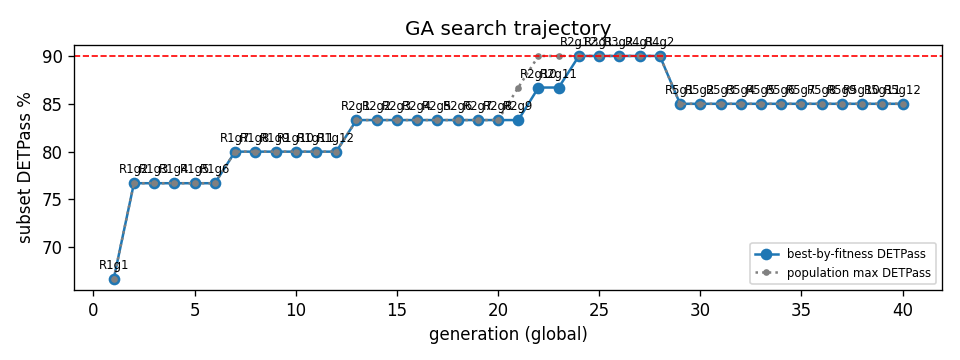

saved -> trajectory.png

채택 이력:
  R1: score 80.0 | adopted (changed) | 변경됨
  R2: score 90.0 | adopted (changed) | 변경됨
  R3: score 90.0 | kept incumbent (no improvement) (regression 0 <= 1) | 변경 없음(incumbent 유지)
  R4: score 90.0 | kept incumbent (no improvement) (regression 0 <= 1) | 변경 없음(incumbent 유지)
  R5: score 85.0 | adopted (changed) (regression 0 <= 1) | 변경됨

실행 요약: z3 예외 직전 flush 이후 0건(전체 누적 0건은 state.json) | premap 백엔드 e5-ft(shortlist 캐시 기록 기준) | 홀드아웃 z3 대상 36/60행

z3 판정 커버리지 (전체 eval_cache, 사유별): {'gt_no_condition': 3781, 'ok': 3481, 'path_count_mismatch': 832, 'pred_unconvertible:parse failed': 175, 'pred_unconvertible:ordered comparison with enum/string': 66, 'gt_unconvertible:parse failed': 5}

규칙 풀 (28):
  - [temporal] Always set period=0 for immediate commands unless specified otherwise
  - [schema] Use exact numeric units and convert units to base units when applicable
  - [schema] Include all relevant receivers and services explicitly in the script
  - [temporal] Always

In [11]:
# ============================================================
# History table + score trajectory + artifacts
# ============================================================
hist = [h for h in history_log if h.get("gen") != "adopt"]
if hist:
    hdf = pd.DataFrame([{**{k: h.get(k) for k in ("round", "gen", "score", "judge_adjusted",
                                                  "fitness", "logic_pct", "tokens", "latency")},
                         "pop_max": (max(p[1] for p in h["population"]) if h.get("population") else None)}
                        for h in hist])
    print(hdf.to_string(index=False))
    try:
        import matplotlib
        matplotlib.use("Agg")
        import matplotlib.pyplot as plt
        fig, ax = plt.subplots(figsize=(8, 3))
        ax.plot(range(1, len(hdf) + 1), hdf["score"], marker="o", label="best-by-fitness DETPass")
        if hdf["pop_max"].notna().any():
            ax.plot(range(1, len(hdf) + 1), hdf["pop_max"], ls=":", marker=".", c="gray",
                    label="population max DETPass")
        ax.legend(fontsize=7)
        for x, (r, g) in enumerate(zip(hdf["round"], hdf["gen"]), 1):
            ax.annotate(f"{r}g{g}", (x, hdf['score'].iloc[x - 1]), fontsize=7, xytext=(0, 6),
                        textcoords="offset points", ha="center")
        ax.axhline(TARGET, ls="--", c="r", lw=1)
        ax.set_xlabel("generation (global)"); ax.set_ylabel("subset DETPass %")
        ax.set_title("GA search trajectory")
        fig.tight_layout(); fig.savefig(ART_DIR / "trajectory.png", dpi=120)
        from IPython.display import Image, display
        display(Image(str(ART_DIR / "trajectory.png")))
        print("saved -> trajectory.png")
    except Exception as exc:
        print("plot skipped:", exc)

print("\n채택 이력:")
_ph = None
for h in history_log:
    if h.get("gen") == "adopt":
        _ch = h.get("chosen_hash") or genome_hash(h["genome"])
        _chg = h["changed"] if "changed" in h else (None if _ph is None else _ch != _ph)
        tag = "" if _chg is None else (" | 변경됨" if _chg else " | 변경 없음(incumbent 유지)")
        tag += derive_gate_tag(h, h.get("prev_hash") or _ph)
        print(f"  {h['round']}: score {h['score']} | {h['note']}{tag}")
        _ph = _ch
state["z3_errors"] = state.get("z3_errors", 0) + Z3_ERRORS
save_state()
print(f"\n실행 요약: z3 예외 직전 flush 이후 {Z3_ERRORS}건(전체 누적 {state['z3_errors']}건은 state.json) | "
      f"premap 백엔드 {SHORTLIST_BACKEND}(shortlist 캐시 기록 기준) | "
      f"홀드아웃 z3 대상 {sum(1 for r in holdout_recs if r.get('logic') is not None)}/{len(holdout_recs)}행")
Z3_ERRORS = 0   # state로 flush 완료 - 셀 재실행 시 이중 집계 방지
_z3_cov = Counter(r.get("z3_note", "legacy(ev1)") for r in eval_cache.values())
print("\nz3 판정 커버리지 (전체 eval_cache, 사유별):", dict(_z3_cov.most_common()))
print(f"\n규칙 풀 ({len(state['rule_pool'])}):")
for r in state["rule_pool"]:
    ro = rule_obj(r)
    print(f"  - [{ro['target_block']}] {ro['rule']}")
print()
for p in sorted(ART_DIR.rglob("*")):
    if p.is_file():
        print(f"{p.stat().st_size:>12,d}  {p.relative_to(ART_DIR)}")